<a href="https://colab.research.google.com/github/jmp7577/Photo4Passport/blob/main/Assignment_Final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!unzip -q Early_Prediction_Airline_Customer_Service_ML_Project.zip
%cd airline_complexity_ml_project

/content/airline_complexity_ml_project


In [2]:
!ls

config.py  Early_Prediction_Airline_Interactions.ipynb	requirements.txt
data	   outputs					scripts
docs	   README.md					src


In [3]:
!ls scripts

01_prepare_airline_data.py		06_leave_one_airline_out.py
02_explore_data.py			07_generate_final_figures.py
03_train_classical_models.py		08_optional_bts_context.py
04_train_sentence_transformer_model.py	run_all.py
05_train_distilbert.py


In [4]:
!pip install -q -r requirements.txt

In [8]:
!mkdir -p data/raw
!mv twcs.csv data/raw/twcs.csv

mv: cannot stat 'twcs.csv': No such file or directory


In [5]:
data/raw/twcs.csv

NameError: name 'data' is not defined

In [9]:
!ls -lh data/raw

total 112M
-rw-r--r-- 1 root root 112M Nov 15 19:50 twcs.csv


In [7]:
!ls -lh data/raw


total 0


In [10]:
import pandas as pd

df = pd.read_csv("data/raw/twcs.csv")

print(df.shape)
df.head()

(628272, 7)


,tweet_id,author_id,inbound,created_at,text,response_tweet_id,in_response_to_tweet_id
0,1,sprintcare,False,Tue Oct 31 22:10:47 +0000 2017,@115712 I understand. I would like to assist y...,2,3.0
1,2,115712,True,Tue Oct 31 22:11:45 +0000 2017,@sprintcare and how do you propose we do that,NaN,1.0
2,3,115712,True,Tue Oct 31 22:08:27 +0000 2017,@sprintcare I have sent several private messag...,1,4.0
3,4,sprintcare,False,Tue Oct 31 21:54:49 +0000 2017,@115712 Please send us a Private Message so th...,3,5.0
4,5,115712,True,Tue Oct 31 21:49:35 +0000 2017,@sprintcare I did.,4,6.0


In [11]:
print(df.columns.tolist())

['tweet_id', 'author_id', 'inbound', 'created_at', 'text', 'response_tweet_id', 'in_response_to_tweet_id']


In [12]:
!python scripts/01_prepare_airline_data.py

Loading /content/airline_complexity_ml_project/data/raw/twcs.csv ...
/content/airline_complexity_ml_project/src/data_utils.py:59: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["created_at"] = pd.to_datetime(df["created_at"], errors="coerce", utc=True)
Raw rows: 628,272
Rows connected to target airlines: 63,887
Saved 15,847 conversations to /content/airline_complexity_ml_project/data/processed/airline_conversations.csv
High-complexity threshold: >= 4 conversational turns
high_complexity
0    0.712879
1    0.287121
Name: share, dtype: float64


In [13]:
import pandas as pd

conversations = pd.read_csv(
    "data/processed/airline_conversations.csv"
)

print(conversations.shape)
conversations.head()

(15847, 14)


,thread_id,airline,turn_count,message_count,duration_hours,start_time,private_redirect_end,full_dialogue,snapshot_1,snapshot_2,snapshot_3,snapshot_4,high_complexity,complexity_threshold_turns
0,626918,AmericanAir,4,4,56425.424722,2011-06-16 13:38:36+00:00,False,CUSTOMER: @americanair Do you have a number to...,CUSTOMER: @americanair Do you have a number to...,CUSTOMER: @americanair Do you have a number to...,CUSTOMER: @americanair Do you have a number to...,CUSTOMER: @americanair Do you have a number to...,1,4
1,539100,British_Airways,3,4,49073.715833,2012-04-27 20:57:49+00:00,False,CUSTOMER: @British_Airways giving me a hard ti...,CUSTOMER: @British_Airways giving me a hard ti...,CUSTOMER: @British_Airways giving me a hard ti...,CUSTOMER: @British_Airways giving me a hard ti...,CUSTOMER: @British_Airways giving me a hard ti...,0,4
2,122514,British_Airways,16,16,23465.964722,2015-03-26 17:21:22+00:00,False,CUSTOMER: @British_Airways having issues with ...,CUSTOMER: @British_Airways having issues with ...,CUSTOMER: @British_Airways having issues with ...,CUSTOMER: @British_Airways having issues with ...,CUSTOMER: @British_Airways having issues with ...,1,4
3,243065,British_Airways,7,8,11445.970278,2016-06-15 17:42:45+00:00,False,CUSTOMER: @British_Airways LCY-JFK 3h delay. C...,CUSTOMER: @British_Airways LCY-JFK 3h delay. C...,CUSTOMER: @British_Airways LCY-JFK 3h delay. C...,CUSTOMER: @British_Airways LCY-JFK 3h delay. C...,CUSTOMER: @British_Airways LCY-JFK 3h delay. C...,1,4
4,399521,British_Airways,5,43,11281.827500,2016-07-08 12:01:18+00:00,False,CUSTOMER: That’s the next five weeks sorted…\n...,CUSTOMER: That’s the next five weeks sorted…\n...,CUSTOMER: That’s the next five weeks sorted…\n...,CUSTOMER: That’s the next five weeks sorted…\n...,CUSTOMER: That’s the next five weeks sorted…\n...,1,4


In [14]:
print(conversations.columns.tolist())

['thread_id', 'airline', 'turn_count', 'message_count', 'duration_hours', 'start_time', 'private_redirect_end', 'full_dialogue', 'snapshot_1', 'snapshot_2', 'snapshot_3', 'snapshot_4', 'high_complexity', 'complexity_threshold_turns']


In [15]:
conversations["high_complexity"].value_counts()

,count
high_complexity,
0,11297
1,4550


In [16]:
conversations["high_complexity"].value_counts(normalize=True)

,proportion
high_complexity,
0,0.712879
1,0.287121


In [17]:
!python scripts/02_explore_data.py

Dataset shape: (15847, 14)

Turn-count summary:
 count    15847.000000
mean         3.044677
std          1.865244
min          2.000000
25%          2.000000
50%          2.000000
75%          4.000000
max         55.000000
Name: turn_count, dtype: float64

Airline counts:
 airline
AmericanAir        4694
Delta              4576
SouthwestAir       3345
British_Airways    3232
Name: count, dtype: int64

Class balance:
 high_complexity
0    0.712879
1    0.287121
Name: proportion, dtype: float64


In [18]:
!ls outputs/figures

01_turn_count_distribution.png	   04_opening_sentiment_by_class.png
02_conversations_by_airline.png    05_opening_words_vs_turns.png
03_complexity_rate_by_airline.png


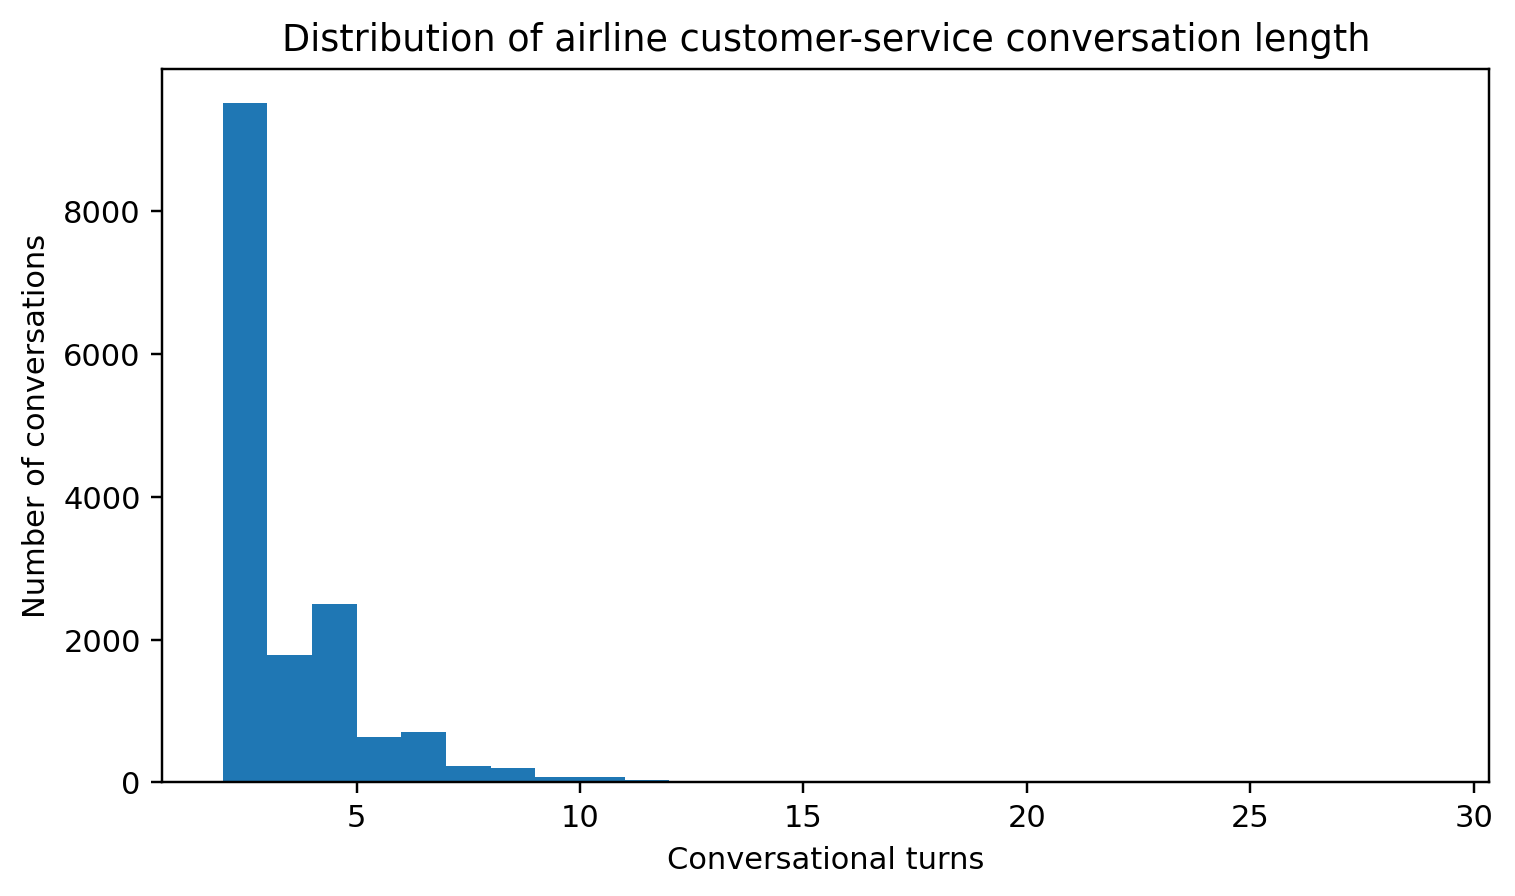

In [19]:
from IPython.display import Image, display

display(
    Image(
        filename="outputs/figures/01_turn_count_distribution.png"
    )
)

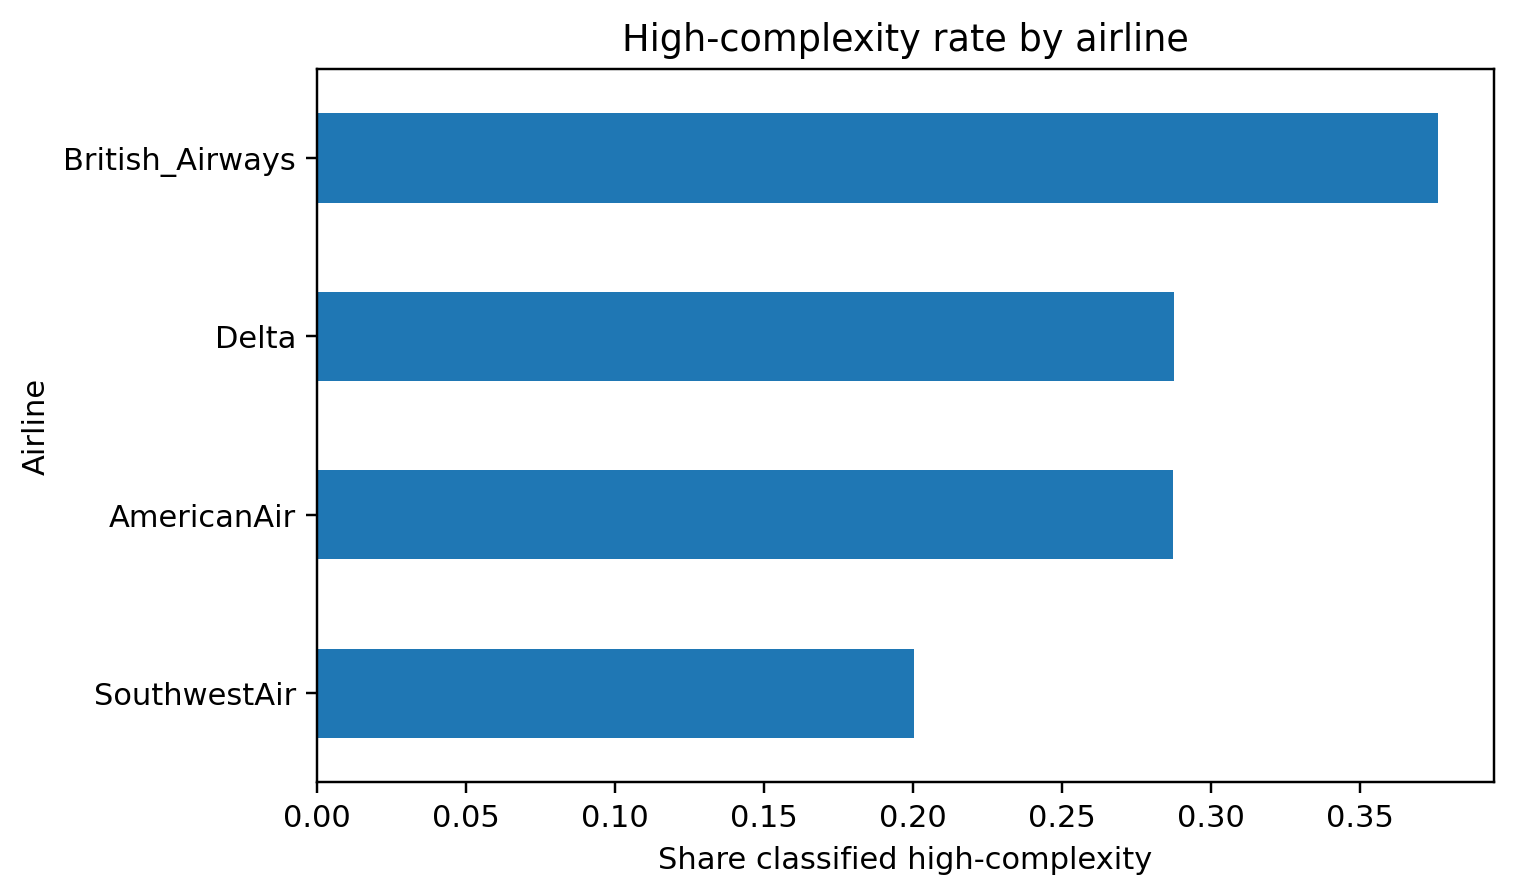

In [20]:
display(
    Image(
        filename="outputs/figures/03_complexity_rate_by_airline.png"
    )
)

In [21]:
!python scripts/03_train_classical_models.py

                   model  snapshot_turns  accuracy  precision   recall       f1  roc_auc  average_precision
       majority_baseline               1  0.712934   0.000000 0.000000 0.000000      NaN                NaN
            tfidf_logreg               1  0.629338   0.399240 0.576923 0.471910 0.657508           0.386757
engineered_random_forest               1  0.694637   0.428922 0.192308 0.265554 0.647675           0.398958
       majority_baseline               2  0.712934   0.000000 0.000000 0.000000      NaN                NaN
            tfidf_logreg               2  0.650473   0.427206 0.638462 0.511894 0.709471           0.456857
engineered_random_forest               2  0.702839   0.472222 0.298901 0.366083 0.690081           0.431962
       majority_baseline               3  0.712934   0.000000 0.000000 0.000000      NaN                NaN
            tfidf_logreg               3  0.795899   0.602815 0.847253 0.704431 0.890116           0.723337
engineered_random_forest    

In [22]:
import pandas as pd

results = pd.read_csv(
    "outputs/metrics/classical_model_summary.csv"
)

results

,model,snapshot_turns,accuracy,precision,recall,f1,roc_auc,average_precision
0,majority_baseline,1,0.712934,0.000000,0.000000,0.000000,NaN,NaN
1,tfidf_logreg,1,0.629338,0.399240,0.576923,0.471910,0.657508,0.386757
2,engineered_random_forest,1,0.694637,0.428922,0.192308,0.265554,0.647675,0.398958
3,majority_baseline,2,0.712934,0.000000,0.000000,0.000000,NaN,NaN
4,tfidf_logreg,2,0.650473,0.427206,0.638462,0.511894,0.709471,0.456857
5,engineered_random_forest,2,0.702839,0.472222,0.298901,0.366083,0.690081,0.431962
6,majority_baseline,3,0.712934,0.000000,0.000000,0.000000,NaN,NaN
7,tfidf_logreg,3,0.795899,0.602815,0.847253,0.704431,0.890116,0.723337
8,engineered_random_forest,3,0.829022,0.672932,0.786813,0.725431,0.896847,0.711902
9,majority_baseline,4,0.712934,0.000000,0.000000,0.000000,NaN,NaN


In [23]:
results.sort_values(
    "f1",
    ascending=False
)

,model,snapshot_turns,accuracy,precision,recall,f1,roc_auc,average_precision
11,engineered_random_forest,4,0.921451,0.829511,0.914286,0.869838,0.971429,0.907876
10,tfidf_logreg,4,0.825552,0.642005,0.886813,0.744808,0.921096,0.814385
8,engineered_random_forest,3,0.829022,0.672932,0.786813,0.725431,0.896847,0.711902
7,tfidf_logreg,3,0.795899,0.602815,0.847253,0.704431,0.890116,0.723337
4,tfidf_logreg,2,0.650473,0.427206,0.638462,0.511894,0.709471,0.456857
1,tfidf_logreg,1,0.629338,0.399240,0.576923,0.471910,0.657508,0.386757
5,engineered_random_forest,2,0.702839,0.472222,0.298901,0.366083,0.690081,0.431962
2,engineered_random_forest,1,0.694637,0.428922,0.192308,0.265554,0.647675,0.398958
3,majority_baseline,2,0.712934,0.000000,0.000000,0.000000,NaN,NaN
0,majority_baseline,1,0.712934,0.000000,0.000000,0.000000,NaN,NaN


In [24]:
!python scripts/06_leave_one_airline_out.py \
    --snapshot-turns 1 \
    --model tfidf

held_out_airline model  snapshot_turns  n_train  n_test  accuracy  precision   recall       f1  roc_auc  average_precision
     AmericanAir tfidf               1    11153    4694  0.619301   0.386797 0.556380 0.456343 0.642648           0.383815
 British_Airways tfidf               1    12615    3232  0.540532   0.437587 0.775493 0.559478 0.600250           0.437716
           Delta tfidf               1    11271    4576  0.654065   0.415453 0.498480 0.453195 0.669045           0.403675
    SouthwestAir tfidf               1    12502    3345  0.720777   0.342857 0.429851 0.381457 0.680731           0.316829


In [25]:
loo = pd.read_csv(
    "outputs/metrics/leave_one_airline_out_tfidf_snapshot_1.csv"
)

loo

,held_out_airline,model,snapshot_turns,n_train,n_test,accuracy,precision,recall,f1,roc_auc,average_precision
0,AmericanAir,tfidf,1,11153,4694,0.619301,0.386797,0.556380,0.456343,0.642648,0.383815
1,British_Airways,tfidf,1,12615,3232,0.540532,0.437587,0.775493,0.559478,0.600250,0.437716
2,Delta,tfidf,1,11271,4576,0.654065,0.415453,0.498480,0.453195,0.669045,0.403675
3,SouthwestAir,tfidf,1,12502,3345,0.720777,0.342857,0.429851,0.381457,0.680731,0.316829


In [26]:
!python scripts/07_generate_final_figures.py

In [27]:
!ls outputs/figures

01_turn_count_distribution.png			  cm_tfidf_snapshot_4.png
02_conversations_by_airline.png			  tfidf_snapshot_1_pr.png
03_complexity_rate_by_airline.png		  tfidf_snapshot_1_roc.png
04_opening_sentiment_by_class.png		  tfidf_snapshot_2_pr.png
05_opening_words_vs_turns.png			  tfidf_snapshot_2_roc.png
10_f1_by_snapshot.png				  tfidf_snapshot_3_pr.png
11_leave_one_airline_out_tfidf_snapshot_1_f1.png  tfidf_snapshot_3_roc.png
cm_tfidf_snapshot_1.png				  tfidf_snapshot_4_pr.png
cm_tfidf_snapshot_2.png				  tfidf_snapshot_4_roc.png
cm_tfidf_snapshot_3.png


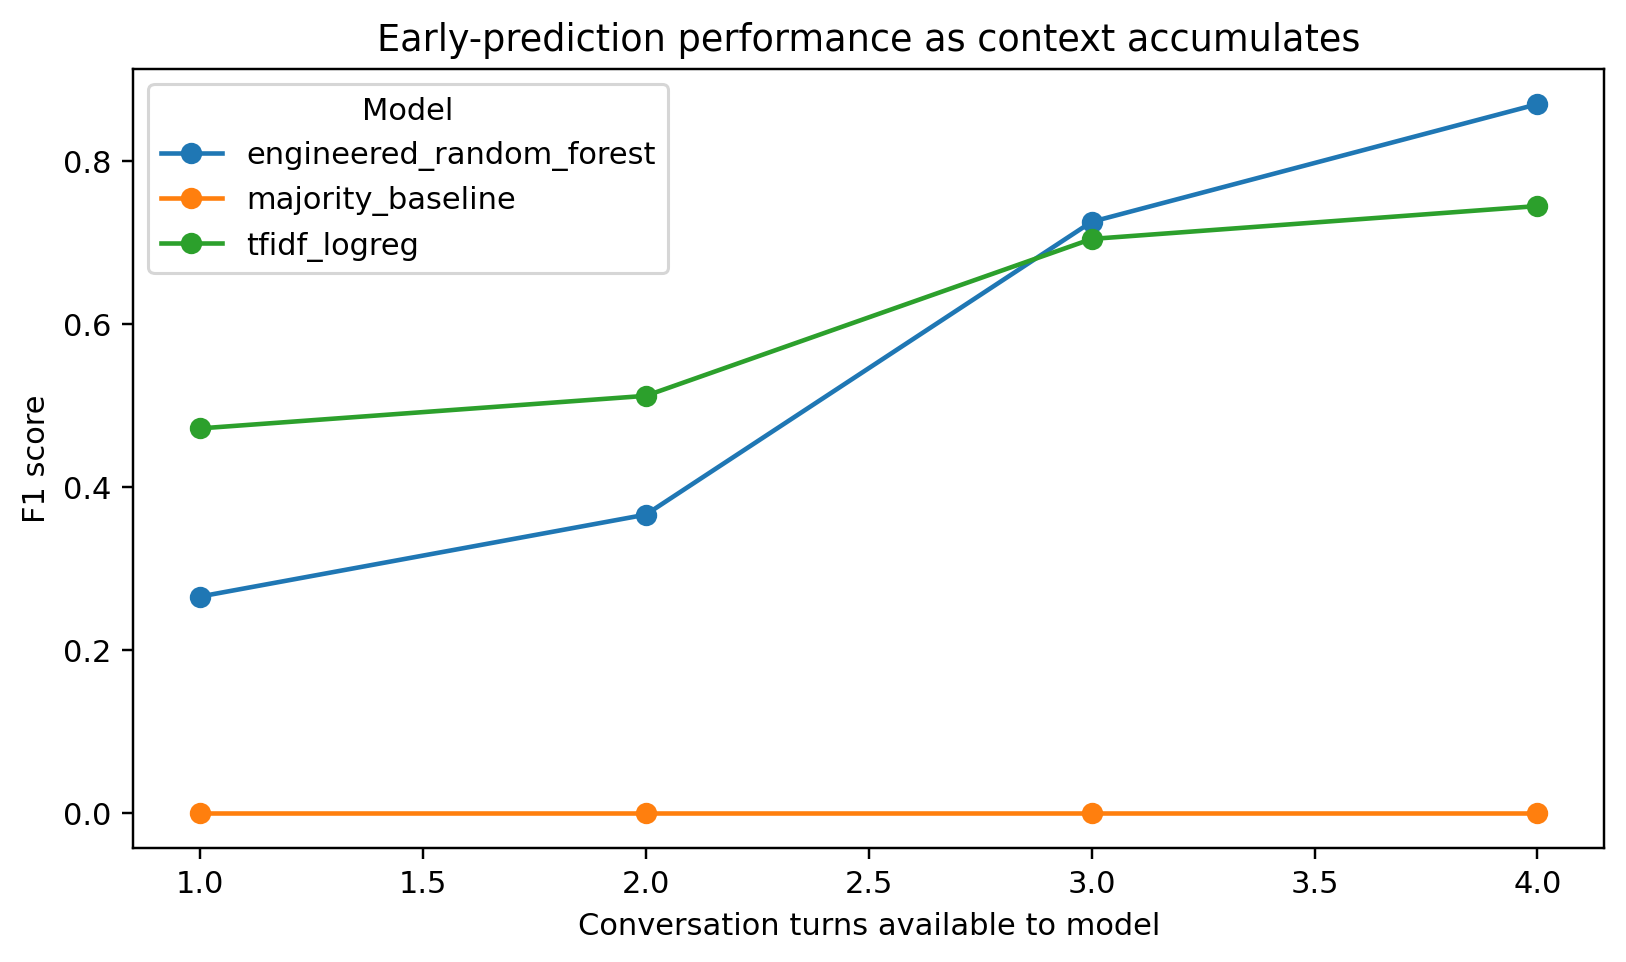

In [28]:
display(
    Image(
        filename="outputs/figures/10_f1_by_snapshot.png"
    )
)

In [29]:
!python scripts/run_all.py


>>> /usr/bin/python3 /content/airline_complexity_ml_project/scripts/01_prepare_airline_data.py
Loading /content/airline_complexity_ml_project/data/raw/twcs.csv ...
/content/airline_complexity_ml_project/src/data_utils.py:59: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["created_at"] = pd.to_datetime(df["created_at"], errors="coerce", utc=True)
Raw rows: 628,272
Rows connected to target airlines: 63,887
Saved 15,847 conversations to /content/airline_complexity_ml_project/data/processed/airline_conversations.csv
High-complexity threshold: >= 4 conversational turns
high_complexity
0    0.712879
1    0.287121
Name: share, dtype: float64

>>> /usr/bin/python3 /content/airline_complexity_ml_project/scripts/02_explore_data.py
Dataset shape: (15847, 14)

Turn-count summary:
 count    15847.000000
mean         3.044677
std          1.865244
min        

In [31]:
import pandas as pd

results = pd.read_csv(
    "outputs/metrics/classical_model_summary.csv"
)

results

,model,snapshot_turns,accuracy,precision,recall,f1,roc_auc,average_precision
0,majority_baseline,1,0.712934,0.000000,0.000000,0.000000,NaN,NaN
1,tfidf_logreg,1,0.629338,0.399240,0.576923,0.471910,0.657508,0.386757
2,engineered_random_forest,1,0.694637,0.428922,0.192308,0.265554,0.647675,0.398958
3,majority_baseline,2,0.712934,0.000000,0.000000,0.000000,NaN,NaN
4,tfidf_logreg,2,0.650473,0.427206,0.638462,0.511894,0.709471,0.456857
5,engineered_random_forest,2,0.702839,0.472222,0.298901,0.366083,0.690081,0.431962
6,majority_baseline,3,0.712934,0.000000,0.000000,0.000000,NaN,NaN
7,tfidf_logreg,3,0.795899,0.602815,0.847253,0.704431,0.890116,0.723337
8,engineered_random_forest,3,0.829022,0.672932,0.786813,0.725431,0.896847,0.711902
9,majority_baseline,4,0.712934,0.000000,0.000000,0.000000,NaN,NaN


In [32]:
results.sort_values(
    ["model", "snapshot_turns"]
)

,model,snapshot_turns,accuracy,precision,recall,f1,roc_auc,average_precision
2,engineered_random_forest,1,0.694637,0.428922,0.192308,0.265554,0.647675,0.398958
5,engineered_random_forest,2,0.702839,0.472222,0.298901,0.366083,0.690081,0.431962
8,engineered_random_forest,3,0.829022,0.672932,0.786813,0.725431,0.896847,0.711902
11,engineered_random_forest,4,0.921451,0.829511,0.914286,0.869838,0.971429,0.907876
0,majority_baseline,1,0.712934,0.000000,0.000000,0.000000,NaN,NaN
3,majority_baseline,2,0.712934,0.000000,0.000000,0.000000,NaN,NaN
6,majority_baseline,3,0.712934,0.000000,0.000000,0.000000,NaN,NaN
9,majority_baseline,4,0.712934,0.000000,0.000000,0.000000,NaN,NaN
1,tfidf_logreg,1,0.629338,0.399240,0.576923,0.471910,0.657508,0.386757
4,tfidf_logreg,2,0.650473,0.427206,0.638462,0.511894,0.709471,0.456857


In [33]:
summary = results.groupby(
    ["model", "snapshot_turns"]
)[["precision", "recall", "f1", "roc_auc"]].mean().reset_index()

summary

,model,snapshot_turns,precision,recall,f1,roc_auc
0,engineered_random_forest,1,0.428922,0.192308,0.265554,0.647675
1,engineered_random_forest,2,0.472222,0.298901,0.366083,0.690081
2,engineered_random_forest,3,0.672932,0.786813,0.725431,0.896847
3,engineered_random_forest,4,0.829511,0.914286,0.869838,0.971429
4,majority_baseline,1,0.000000,0.000000,0.000000,NaN
5,majority_baseline,2,0.000000,0.000000,0.000000,NaN
6,majority_baseline,3,0.000000,0.000000,0.000000,NaN
7,majority_baseline,4,0.000000,0.000000,0.000000,NaN
8,tfidf_logreg,1,0.399240,0.576923,0.471910,0.657508
9,tfidf_logreg,2,0.427206,0.638462,0.511894,0.709471


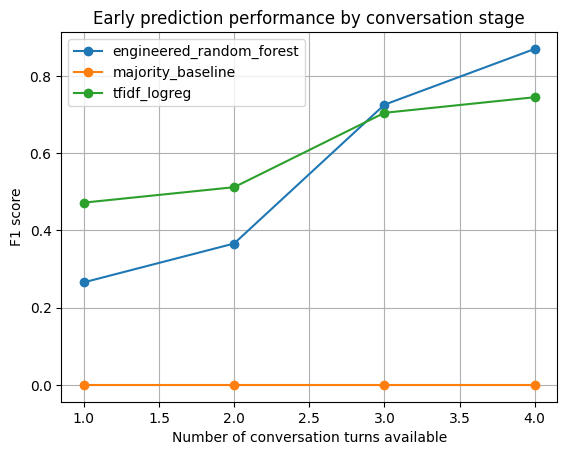

In [34]:
import matplotlib.pyplot as plt

for model in summary["model"].unique():
    temp = summary[summary["model"] == model]

    plt.plot(
        temp["snapshot_turns"],
        temp["f1"],
        marker="o",
        label=model
    )

plt.xlabel("Number of conversation turns available")
plt.ylabel("F1 score")
plt.title("Early prediction performance by conversation stage")
plt.legend()
plt.grid(True)
plt.show()

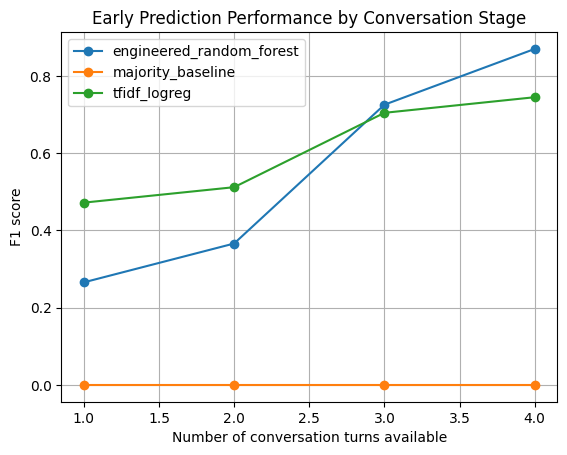

In [35]:
plt.figure()

for model in summary["model"].unique():
    temp = summary[summary["model"] == model]

    plt.plot(
        temp["snapshot_turns"],
        temp["f1"],
        marker="o",
        label=model
    )

plt.xlabel("Number of conversation turns available")
plt.ylabel("F1 score")
plt.title("Early Prediction Performance by Conversation Stage")
plt.legend()
plt.grid(True)

plt.savefig(
    "outputs/figures/f1_by_conversation_stage.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [36]:
!python scripts/06_leave_one_airline_out.py \
    --snapshot-turns 1 \
    --model tfidf

held_out_airline model  snapshot_turns  n_train  n_test  accuracy  precision   recall       f1  roc_auc  average_precision
     AmericanAir tfidf               1    11153    4694  0.619301   0.386797 0.556380 0.456343 0.642648           0.383815
 British_Airways tfidf               1    12615    3232  0.540532   0.437587 0.775493 0.559478 0.600250           0.437716
           Delta tfidf               1    11271    4576  0.654065   0.415453 0.498480 0.453195 0.669045           0.403675
    SouthwestAir tfidf               1    12502    3345  0.720777   0.342857 0.429851 0.381457 0.680731           0.316829


In [37]:
loo1 = pd.read_csv(
    "outputs/metrics/leave_one_airline_out_tfidf_snapshot_1.csv"
)

loo1

,held_out_airline,model,snapshot_turns,n_train,n_test,accuracy,precision,recall,f1,roc_auc,average_precision
0,AmericanAir,tfidf,1,11153,4694,0.619301,0.386797,0.556380,0.456343,0.642648,0.383815
1,British_Airways,tfidf,1,12615,3232,0.540532,0.437587,0.775493,0.559478,0.600250,0.437716
2,Delta,tfidf,1,11271,4576,0.654065,0.415453,0.498480,0.453195,0.669045,0.403675
3,SouthwestAir,tfidf,1,12502,3345,0.720777,0.342857,0.429851,0.381457,0.680731,0.316829


In [38]:
!python scripts/06_leave_one_airline_out.py \
    --snapshot-turns 2 \
    --model tfidf

held_out_airline model  snapshot_turns  n_train  n_test  accuracy  precision   recall       f1  roc_auc  average_precision
     AmericanAir tfidf               2    11153    4694  0.637836   0.410296 0.597181 0.486405 0.681016           0.432216
 British_Airways tfidf               2    12615    3232  0.549196   0.445598 0.811678 0.575342 0.631267           0.462906
           Delta tfidf               2    11271    4576  0.673077   0.453560 0.667933 0.540258 0.724512           0.470732
    SouthwestAir tfidf               2    12502    3345  0.756054   0.411622 0.507463 0.454545 0.740611           0.404208


In [39]:
!python scripts/06_leave_one_airline_out.py \
    --snapshot-turns 3 \
    --model tfidf

held_out_airline model  snapshot_turns  n_train  n_test  accuracy  precision   recall       f1  roc_auc  average_precision
     AmericanAir tfidf               3    11153    4694  0.766297   0.686478 0.342730 0.457199 0.821158           0.620754
 British_Airways tfidf               3    12615    3232  0.722153   0.672451 0.509868 0.579981 0.794592           0.665586
           Delta tfidf               3    11271    4576  0.772290   0.675641 0.400456 0.502863 0.820815           0.612228
    SouthwestAir tfidf               3    12502    3345  0.821824   0.701087 0.192537 0.302108 0.830398           0.559970


In [40]:
!python scripts/07_generate_final_figures.py

In [41]:
!ls -lh outputs/figures

total 1.5M
-rw-r--r-- 1 root root  56K Nov 15 20:07 01_turn_count_distribution.png
-rw-r--r-- 1 root root  50K Nov 15 20:07 02_conversations_by_airline.png
-rw-r--r-- 1 root root  50K Nov 15 20:07 03_complexity_rate_by_airline.png
-rw-r--r-- 1 root root  61K Nov 15 20:07 04_opening_sentiment_by_class.png
-rw-r--r-- 1 root root  74K Nov 15 20:07 05_opening_words_vs_turns.png
-rw-r--r-- 1 root root  98K Nov 15 20:21 10_f1_by_snapshot.png
-rw-r--r-- 1 root root  46K Nov 15 20:21 11_leave_one_airline_out_tfidf_snapshot_1_f1.png
-rw-r--r-- 1 root root  47K Nov 15 20:21 11_leave_one_airline_out_tfidf_snapshot_2_f1.png
-rw-r--r-- 1 root root  47K Nov 15 20:21 11_leave_one_airline_out_tfidf_snapshot_3_f1.png
-rw-r--r-- 1 root root  61K Nov 15 20:07 cm_tfidf_snapshot_1.png
-rw-r--r-- 1 root root  61K Nov 15 20:07 cm_tfidf_snapshot_2.png
-rw-r--r-- 1 root root  65K Nov 15 20:07 cm_tfidf_snapshot_3.png
-rw-r--r-- 1 root root  68K Nov 15 20:08 cm_tfidf_snapshot_4.png
-rw-r--r-- 1 root root 138K No


 01_turn_count_distribution.png


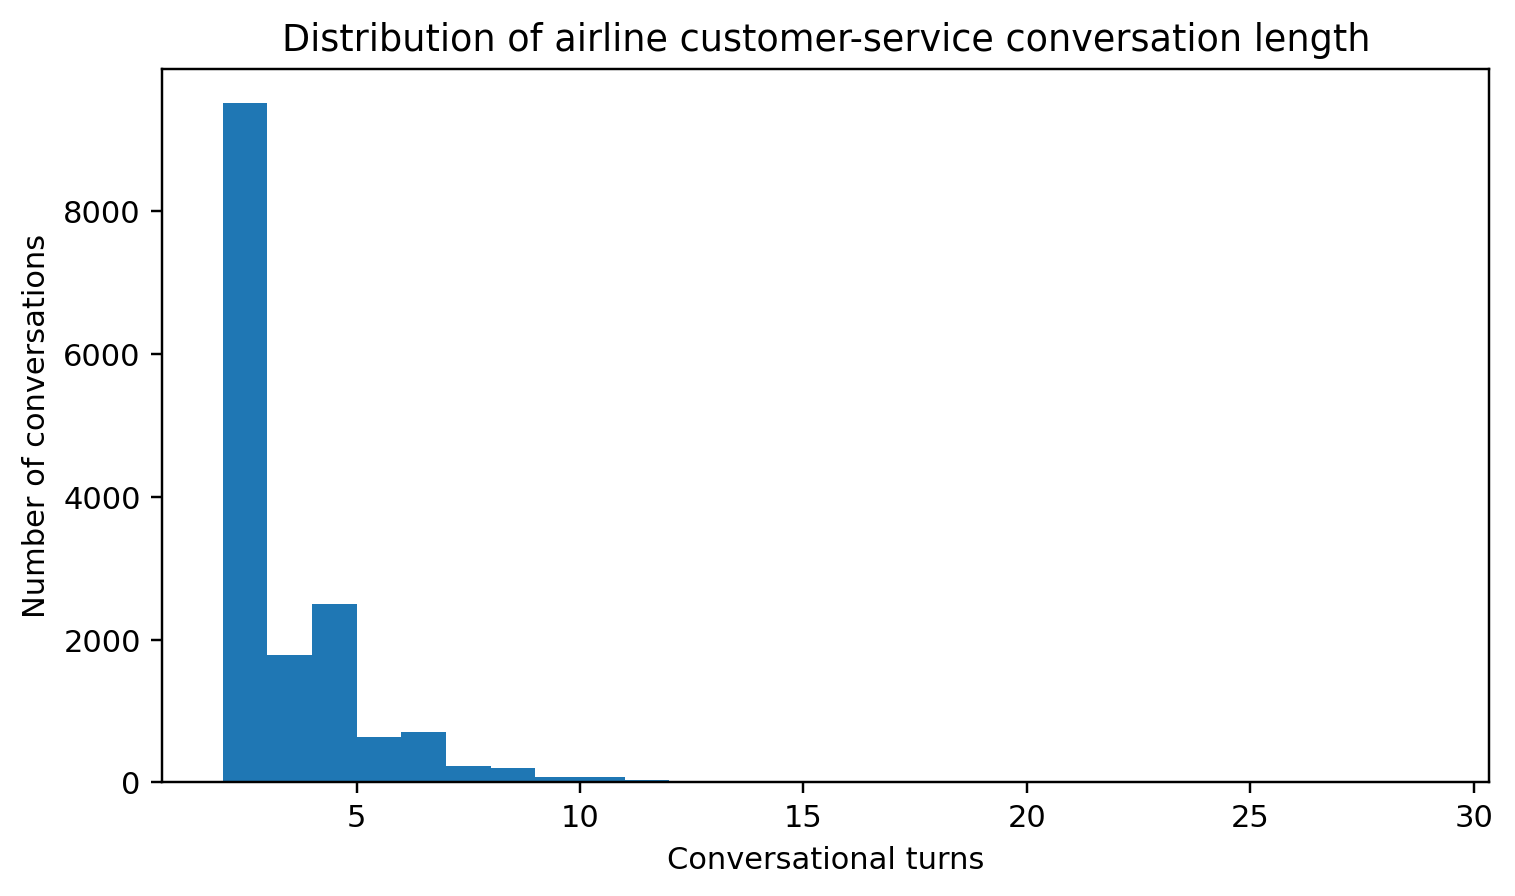


 02_conversations_by_airline.png


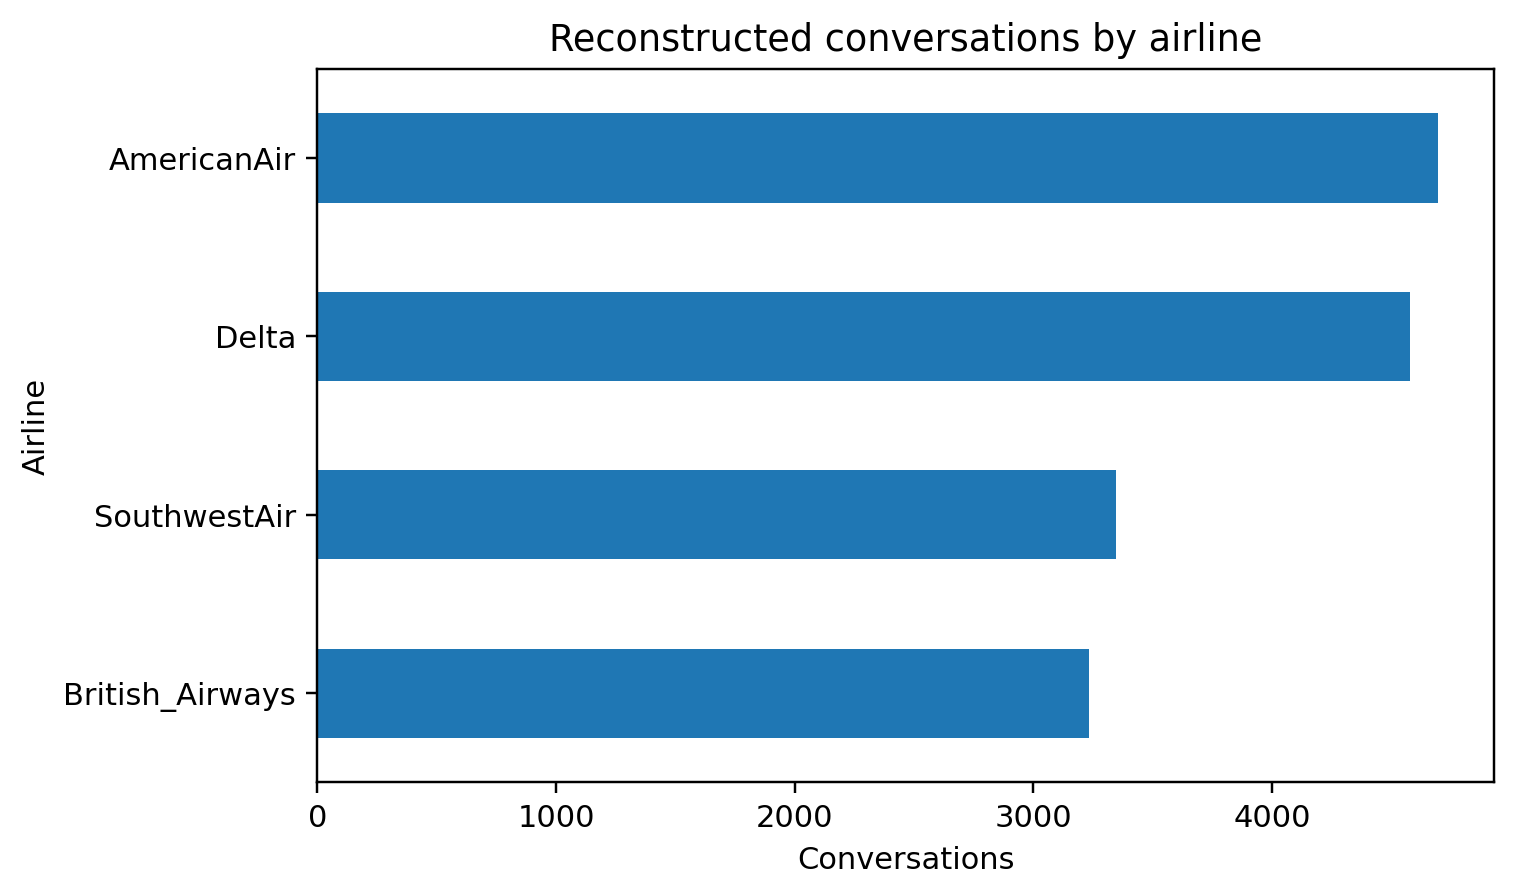


 03_complexity_rate_by_airline.png


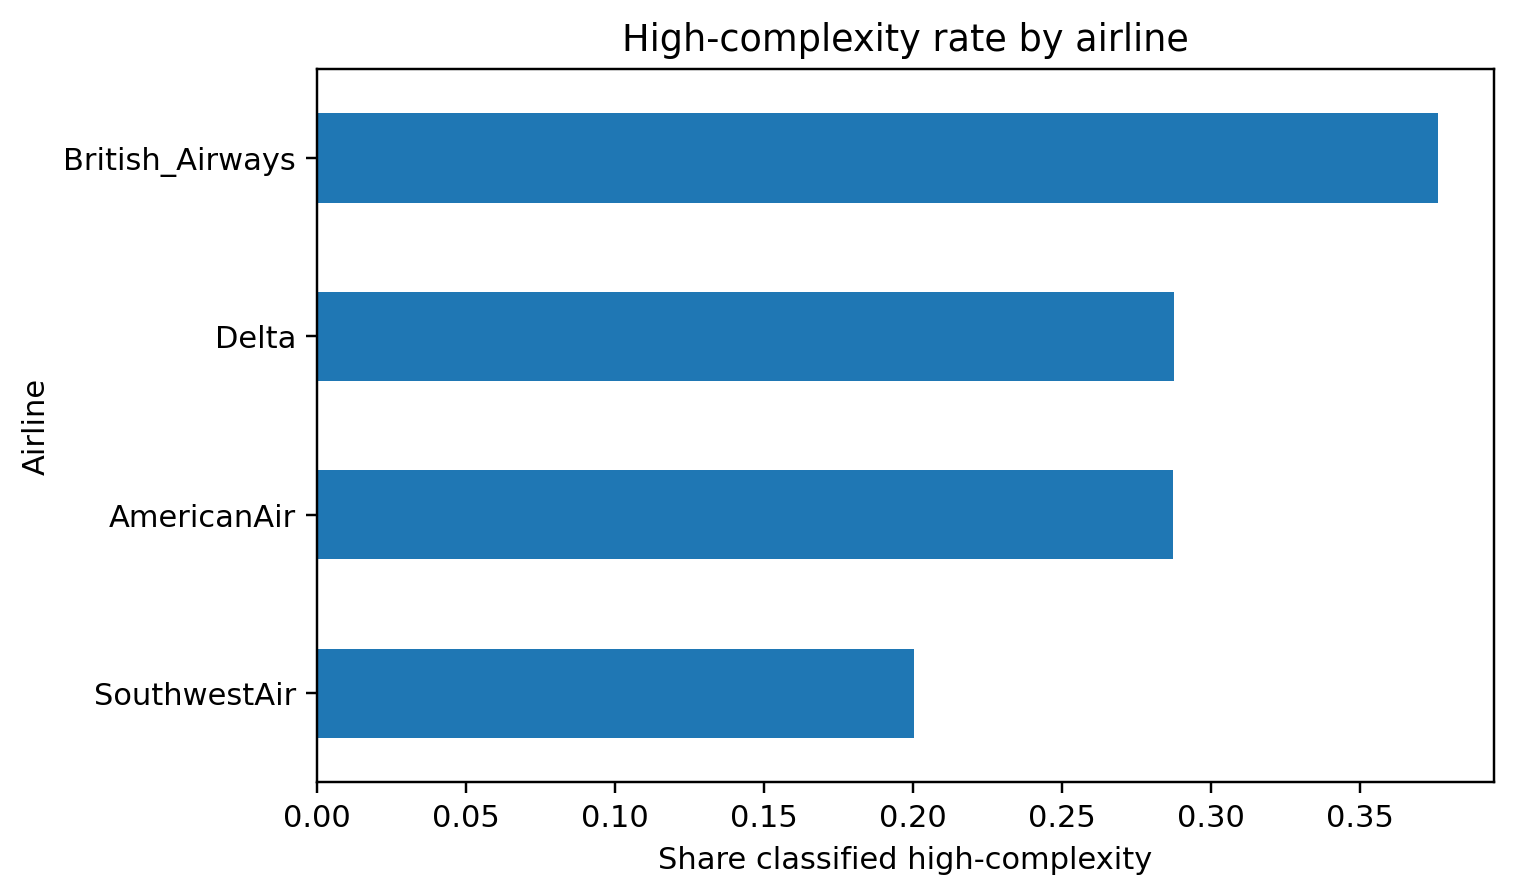


 04_opening_sentiment_by_class.png


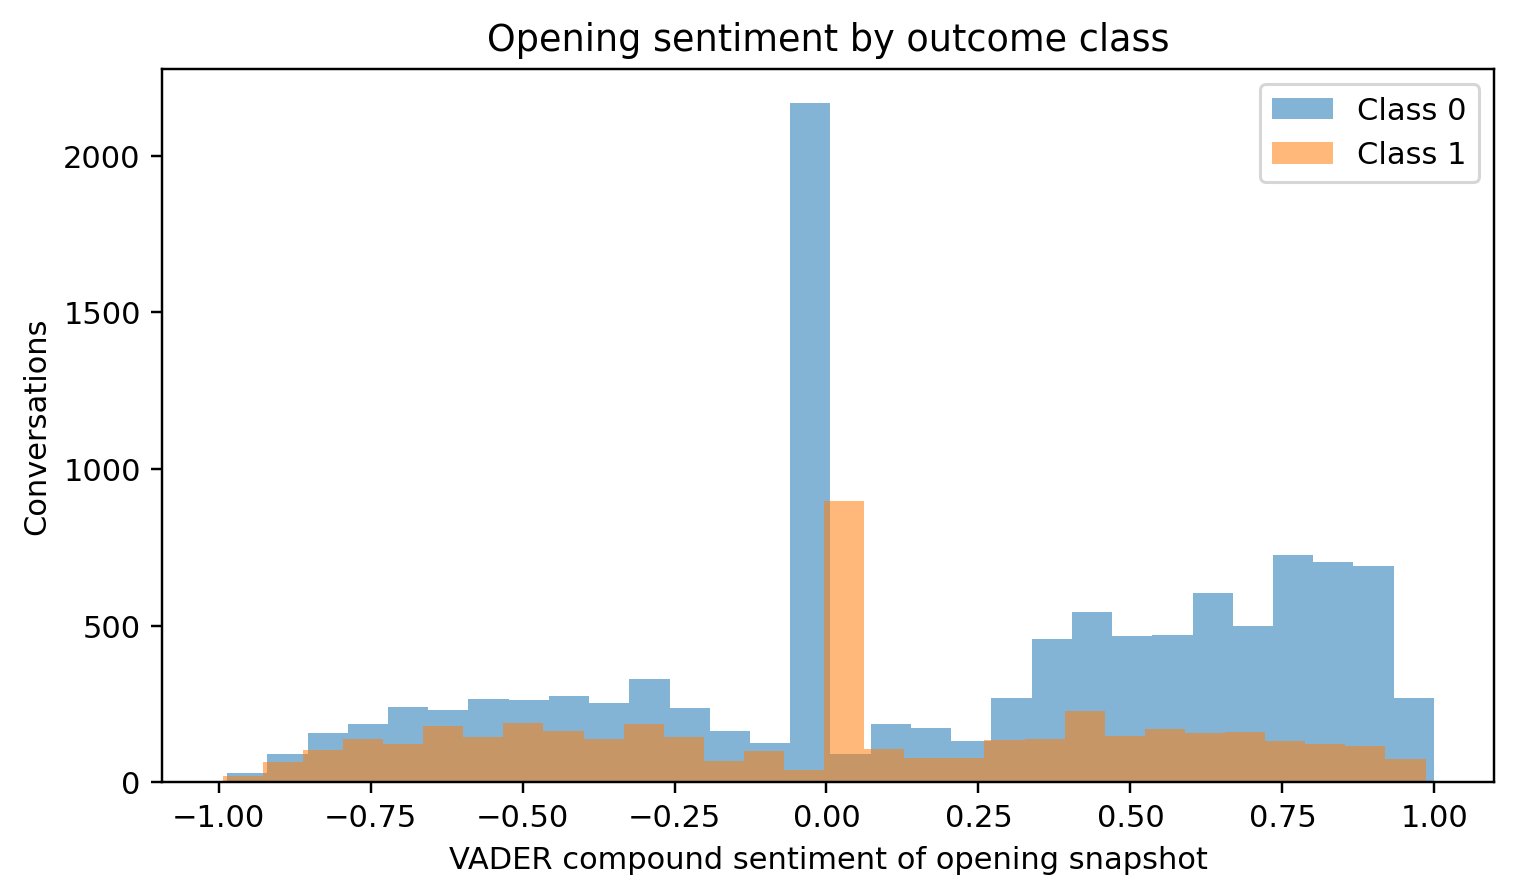


 05_opening_words_vs_turns.png


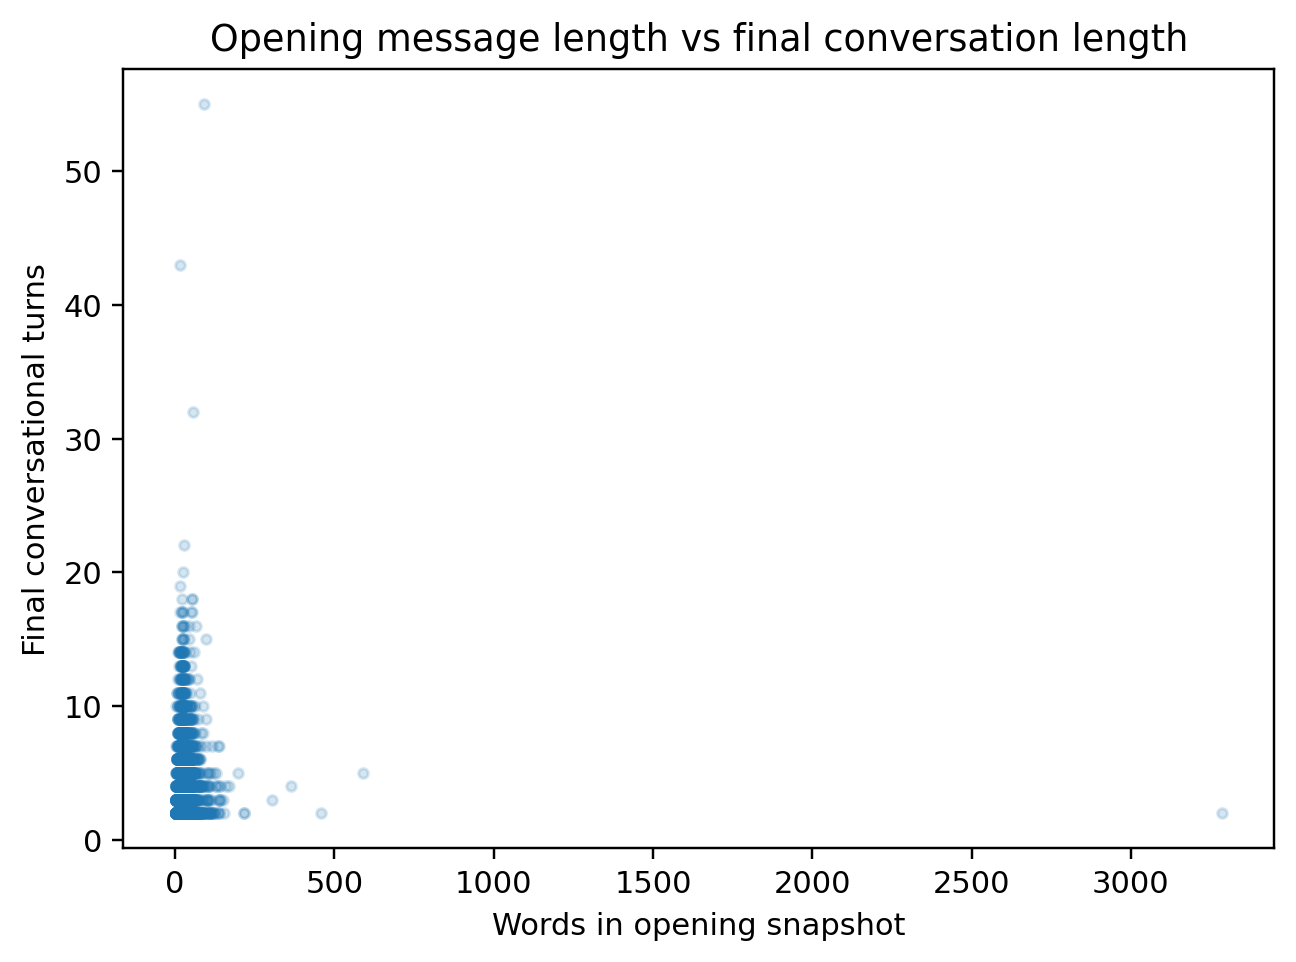


 10_f1_by_snapshot.png


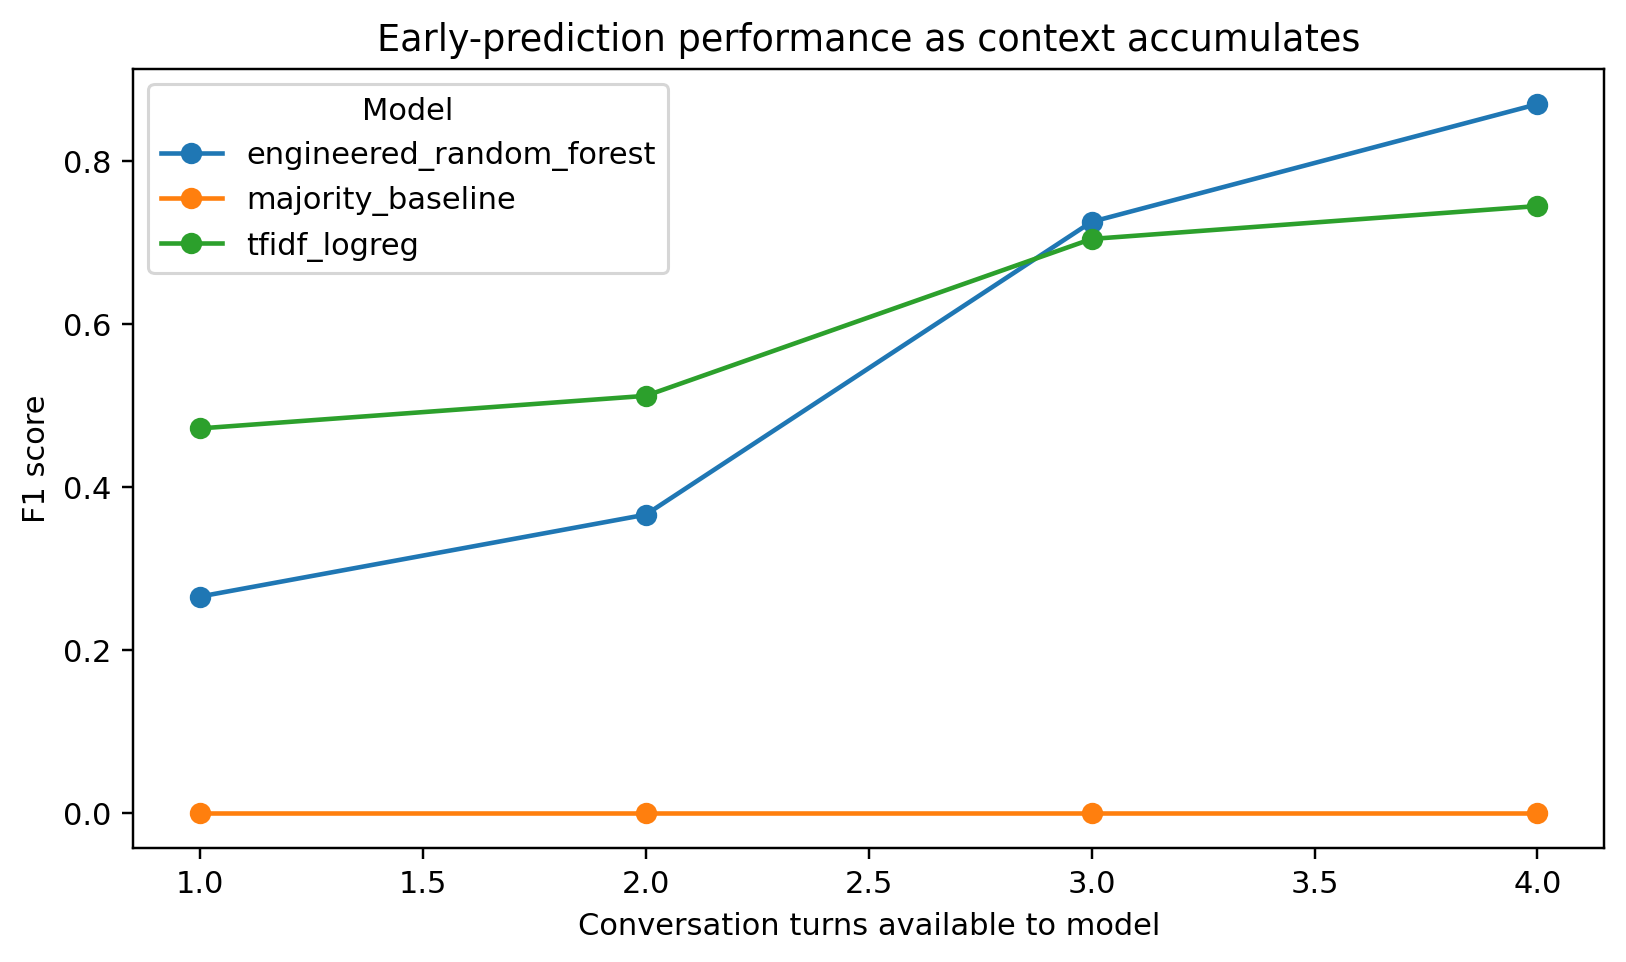


 11_leave_one_airline_out_tfidf_snapshot_1_f1.png


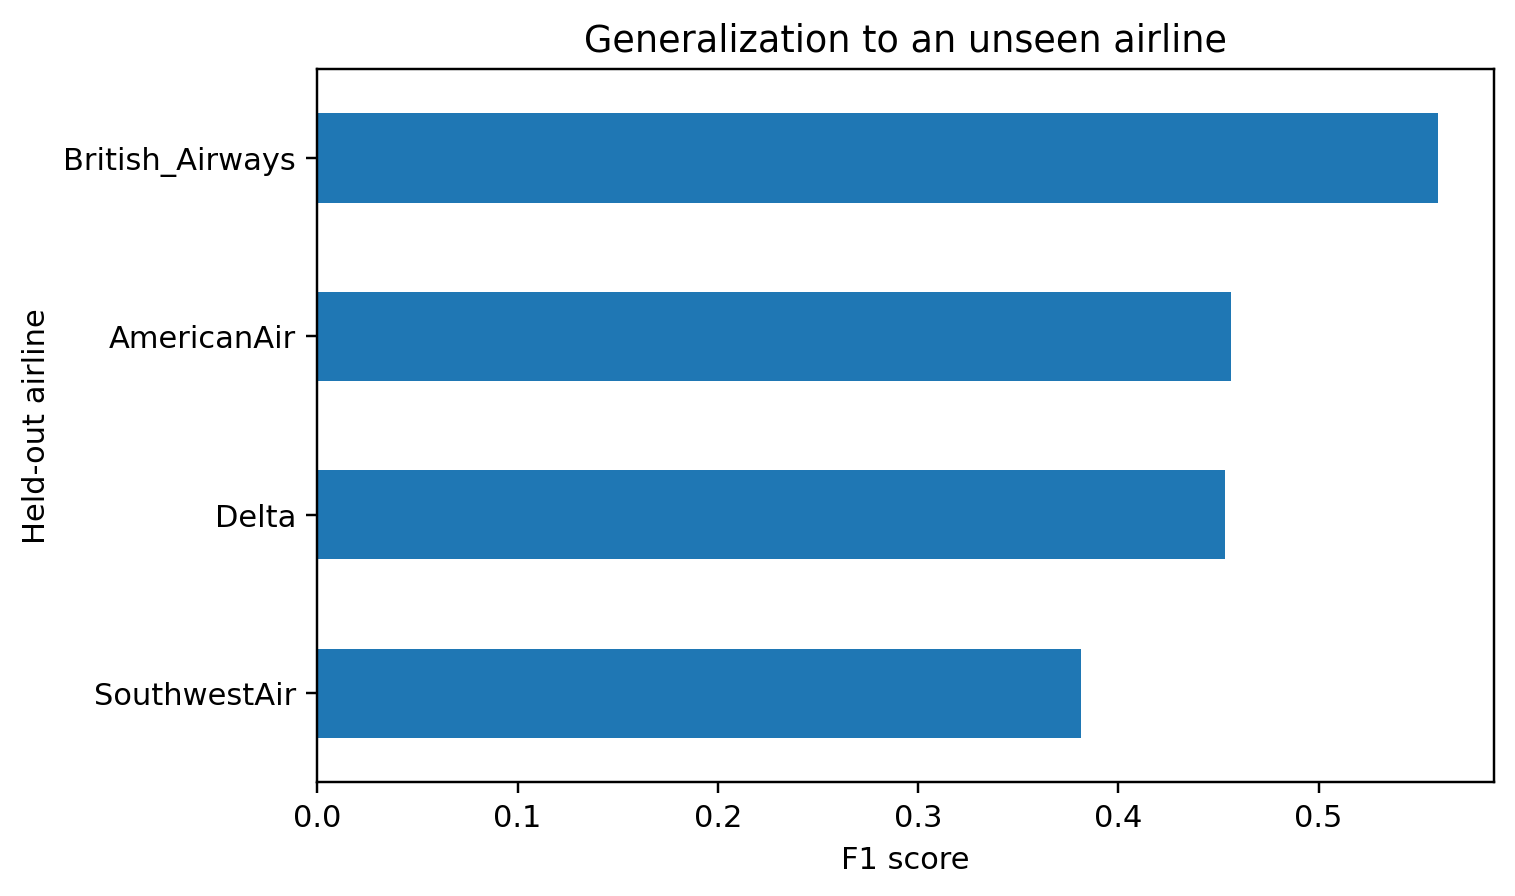


 11_leave_one_airline_out_tfidf_snapshot_2_f1.png


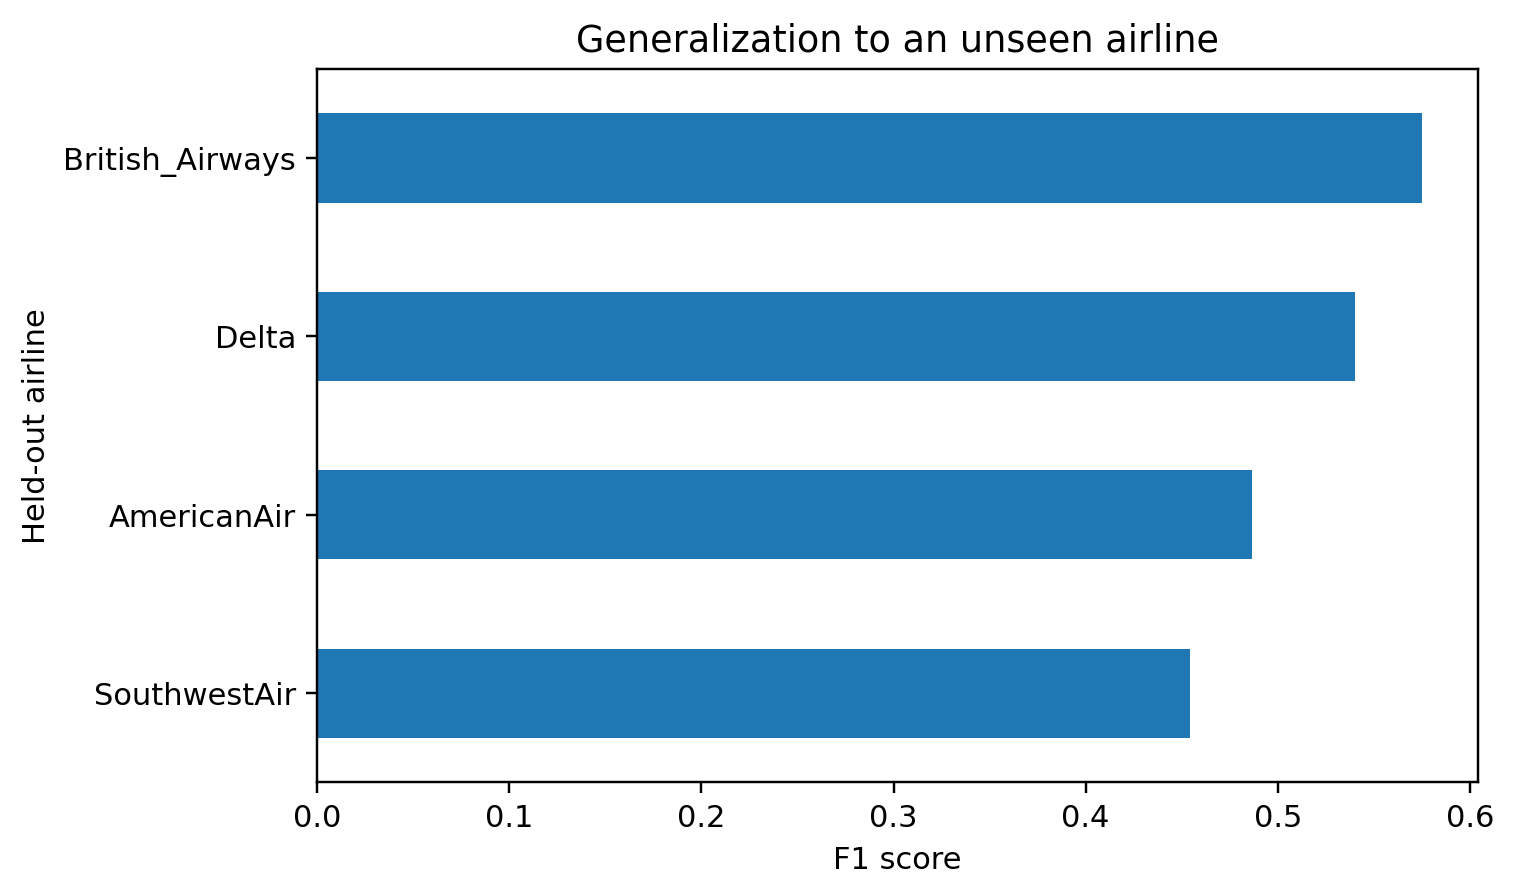


 11_leave_one_airline_out_tfidf_snapshot_3_f1.png


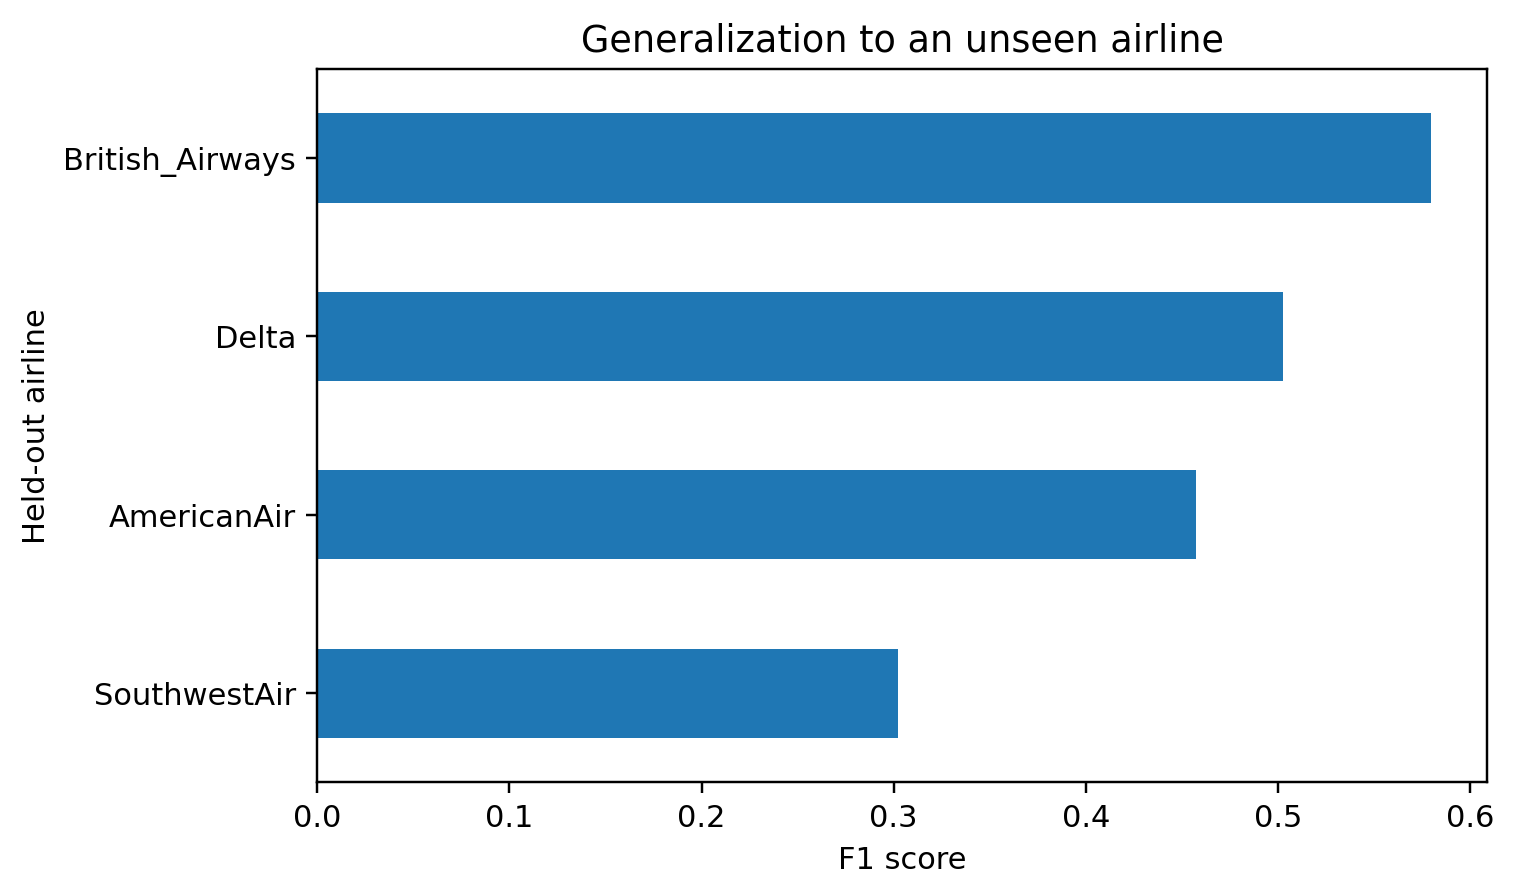


 cm_tfidf_snapshot_1.png


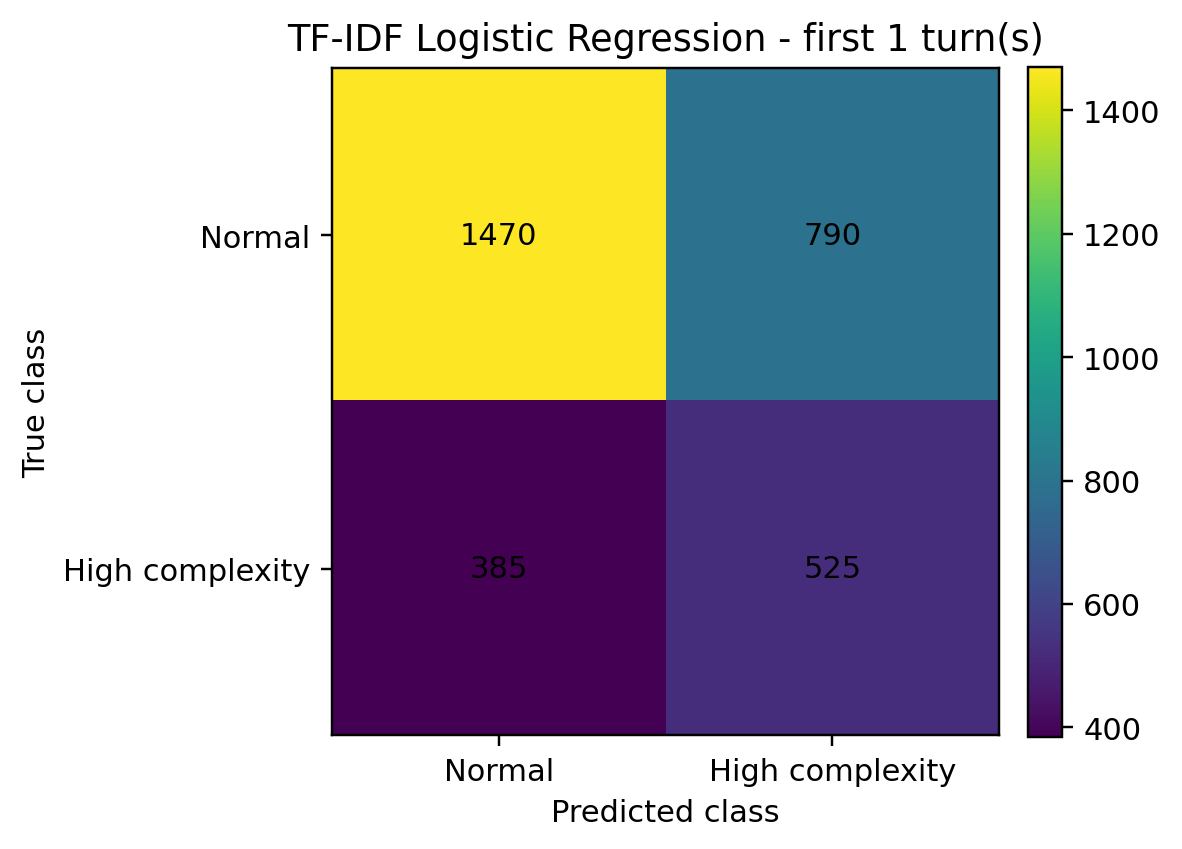


 cm_tfidf_snapshot_2.png


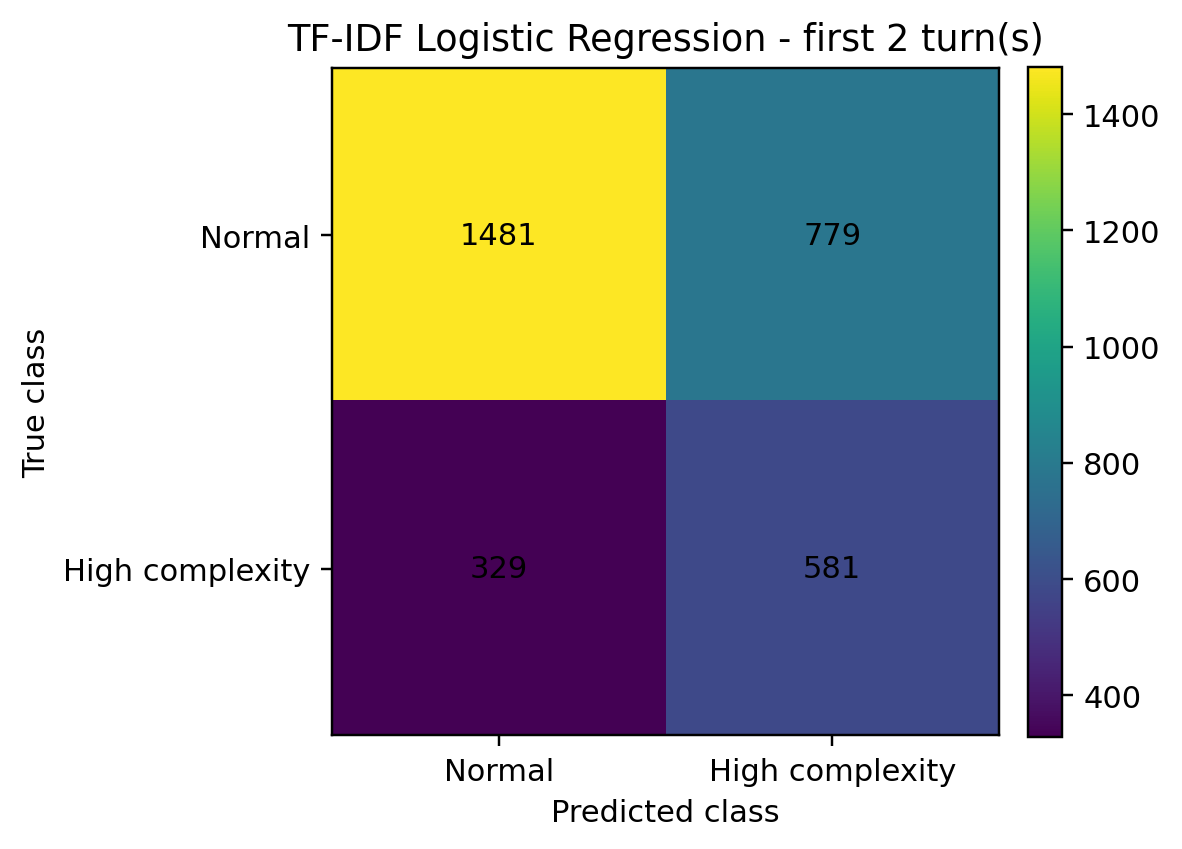


 cm_tfidf_snapshot_3.png


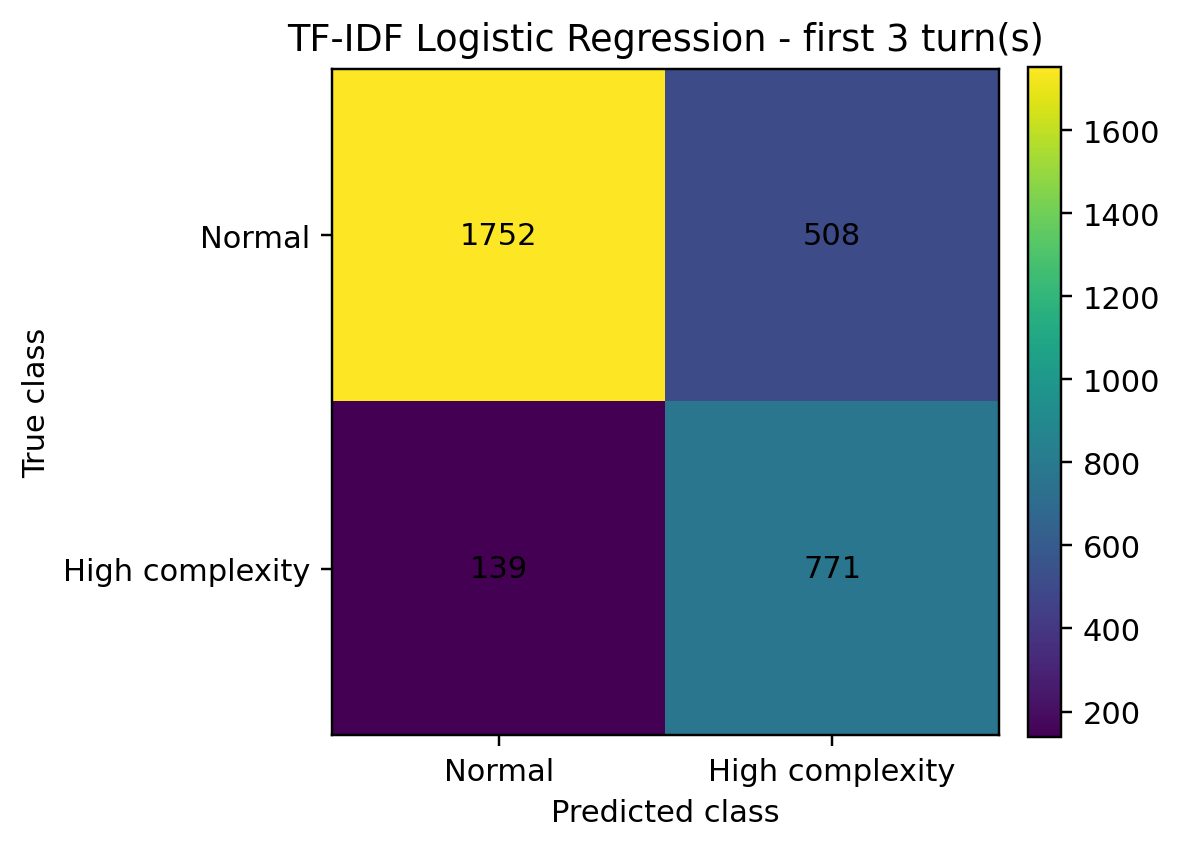


 cm_tfidf_snapshot_4.png


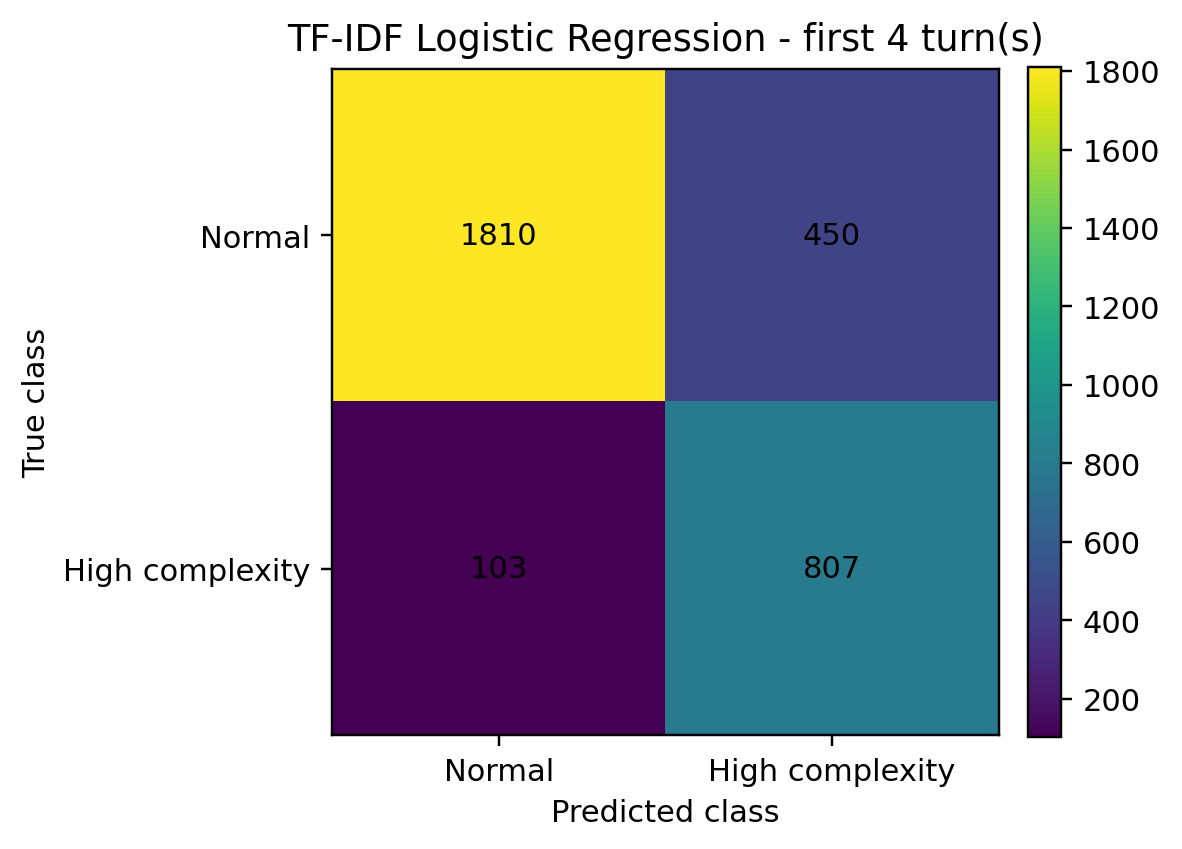


 f1_by_conversation_stage.png


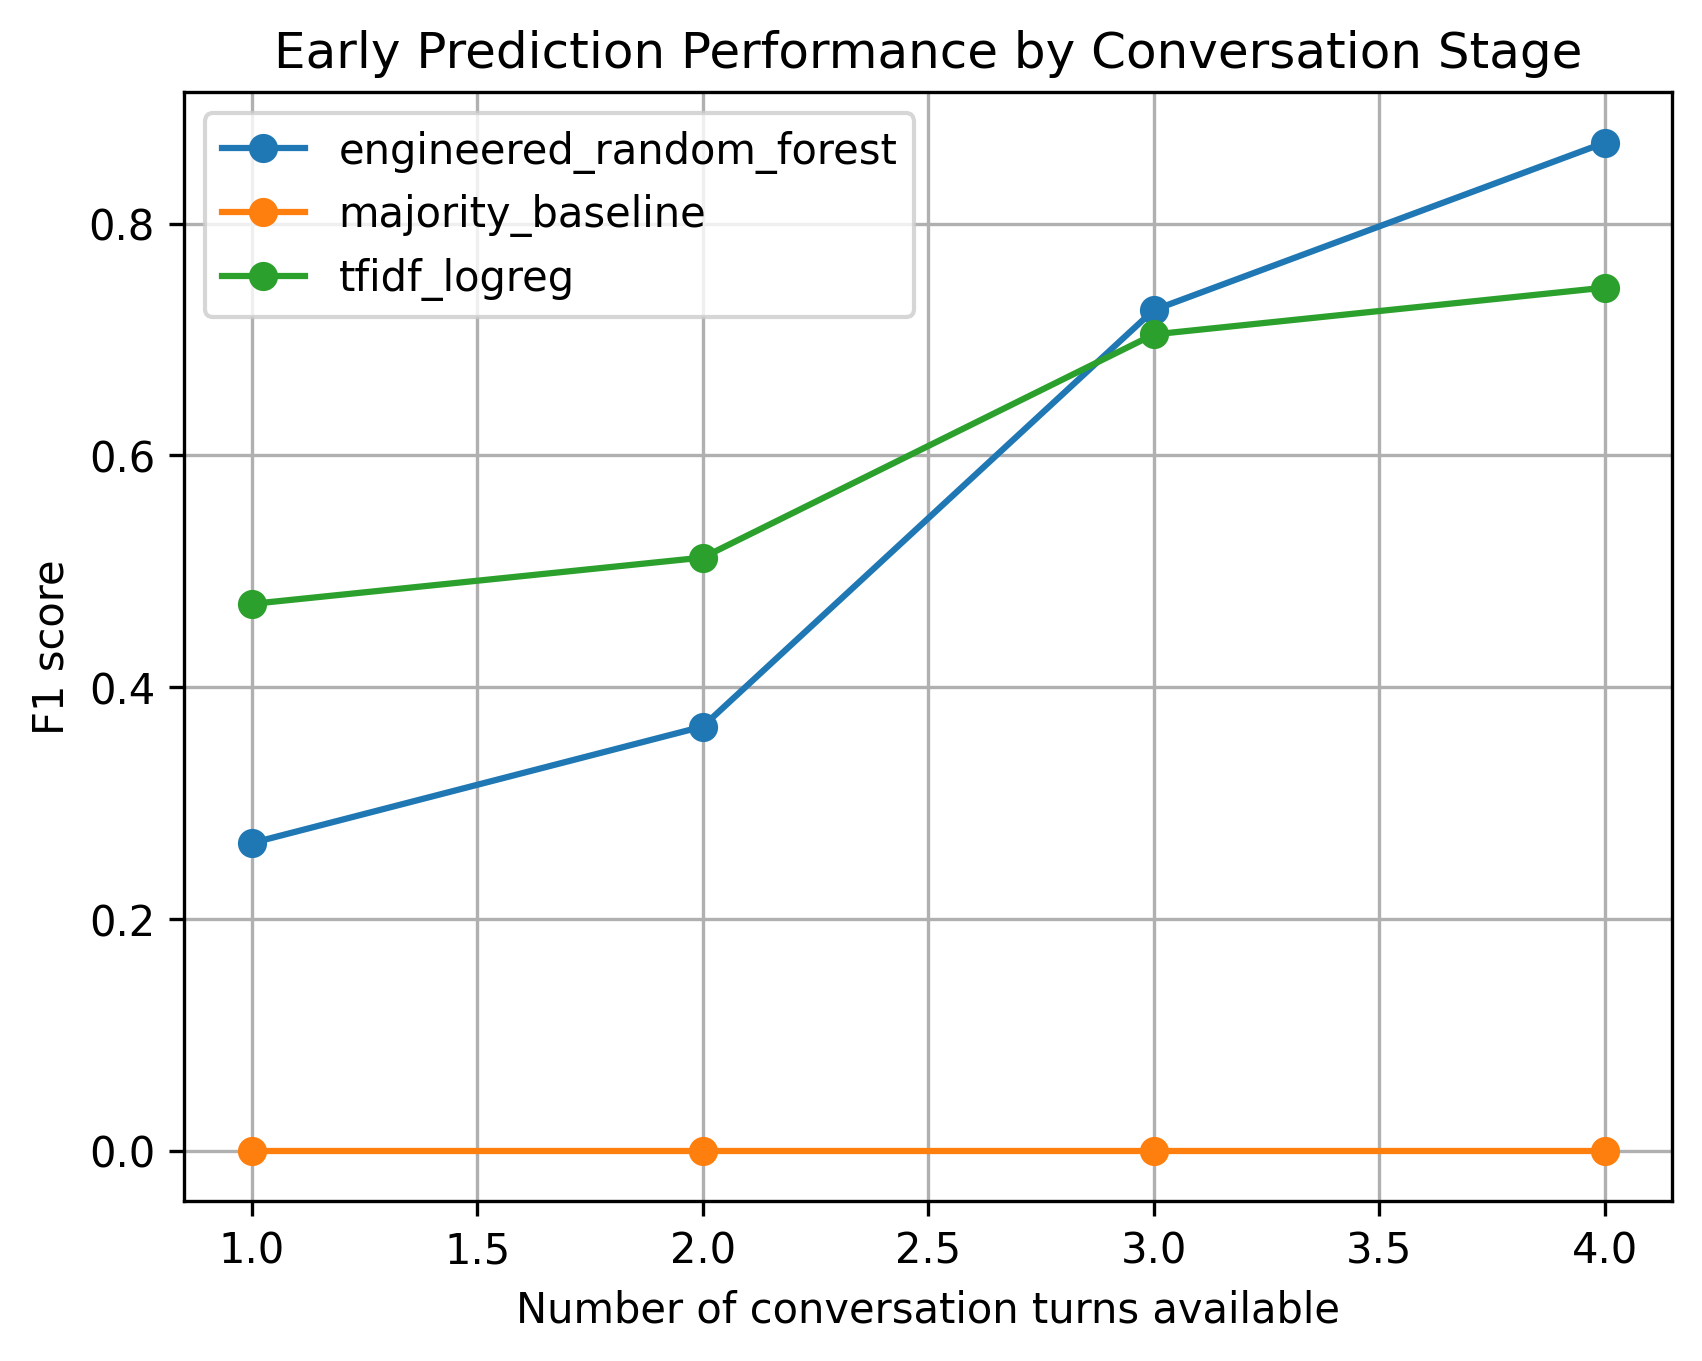


 tfidf_snapshot_1_pr.png


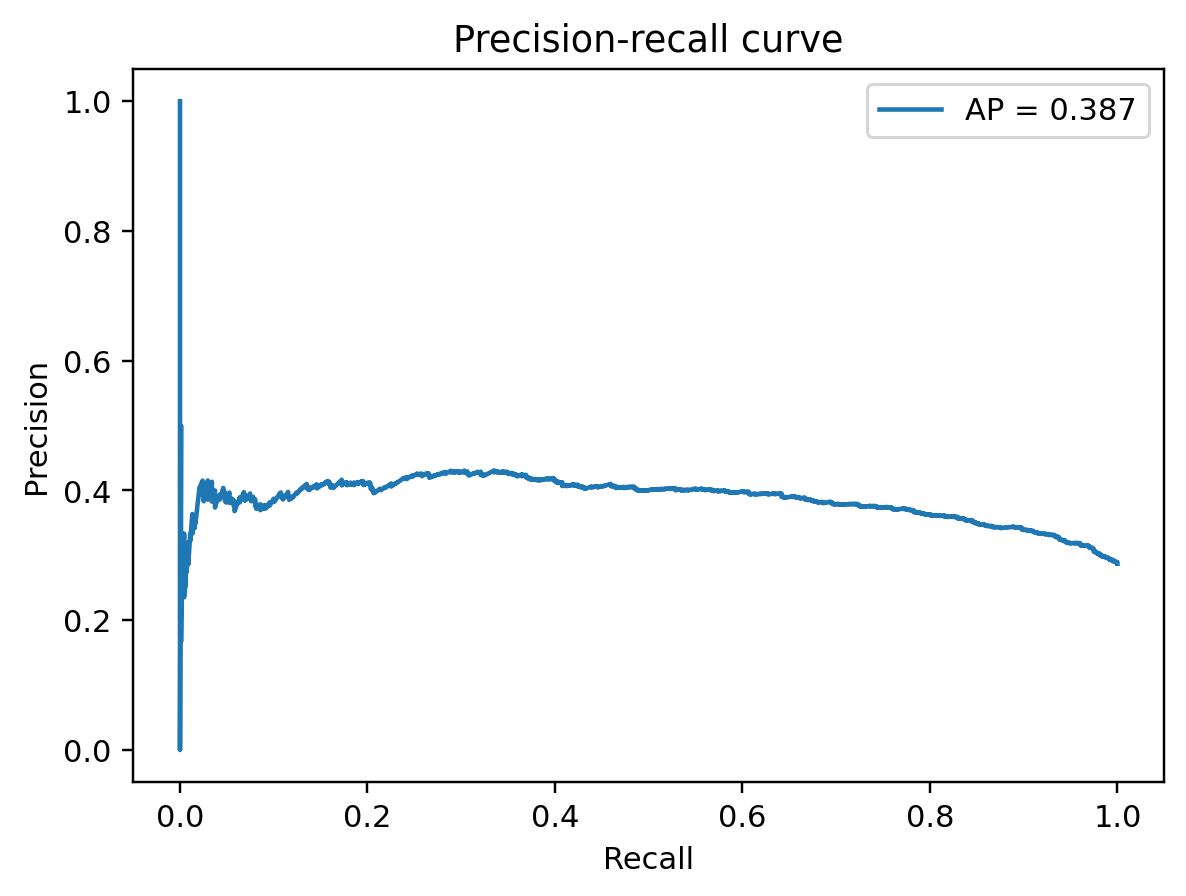


 tfidf_snapshot_1_roc.png


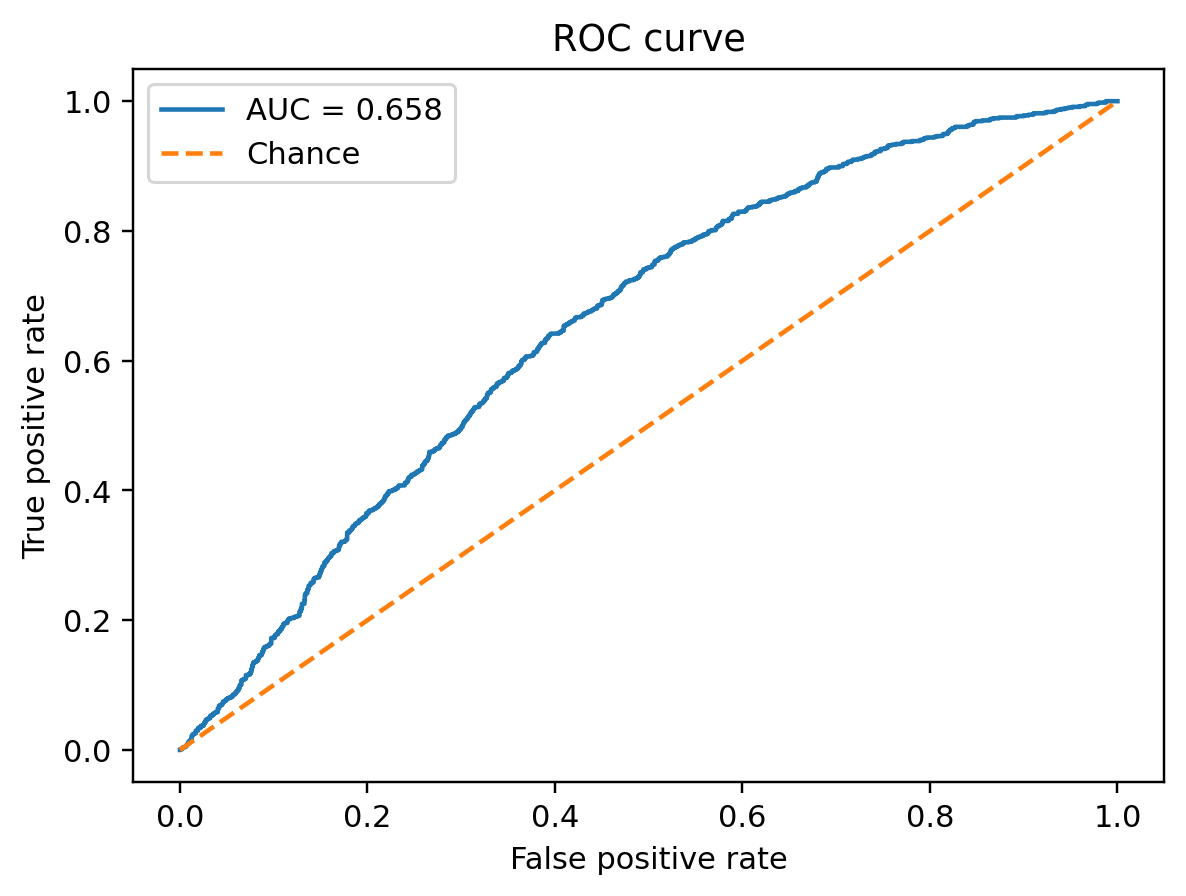


 tfidf_snapshot_2_pr.png


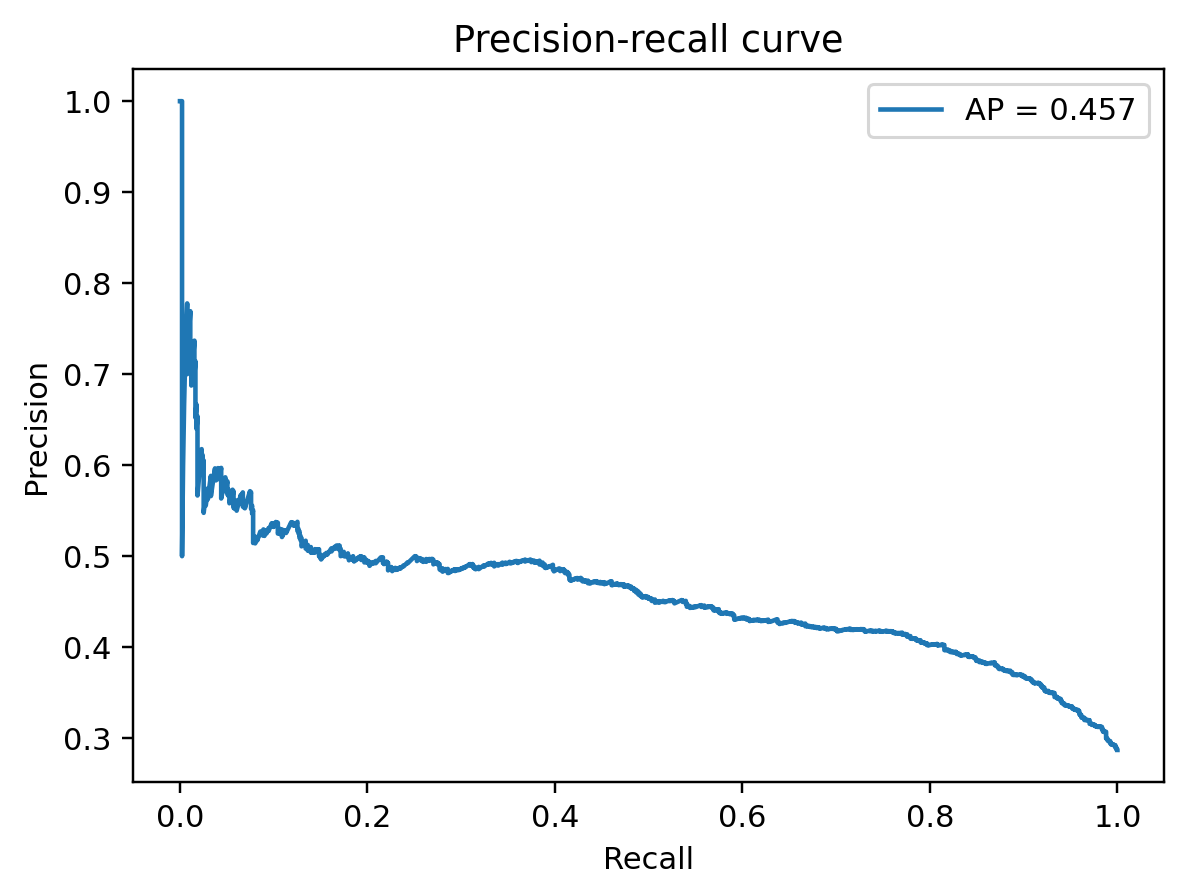


 tfidf_snapshot_2_roc.png


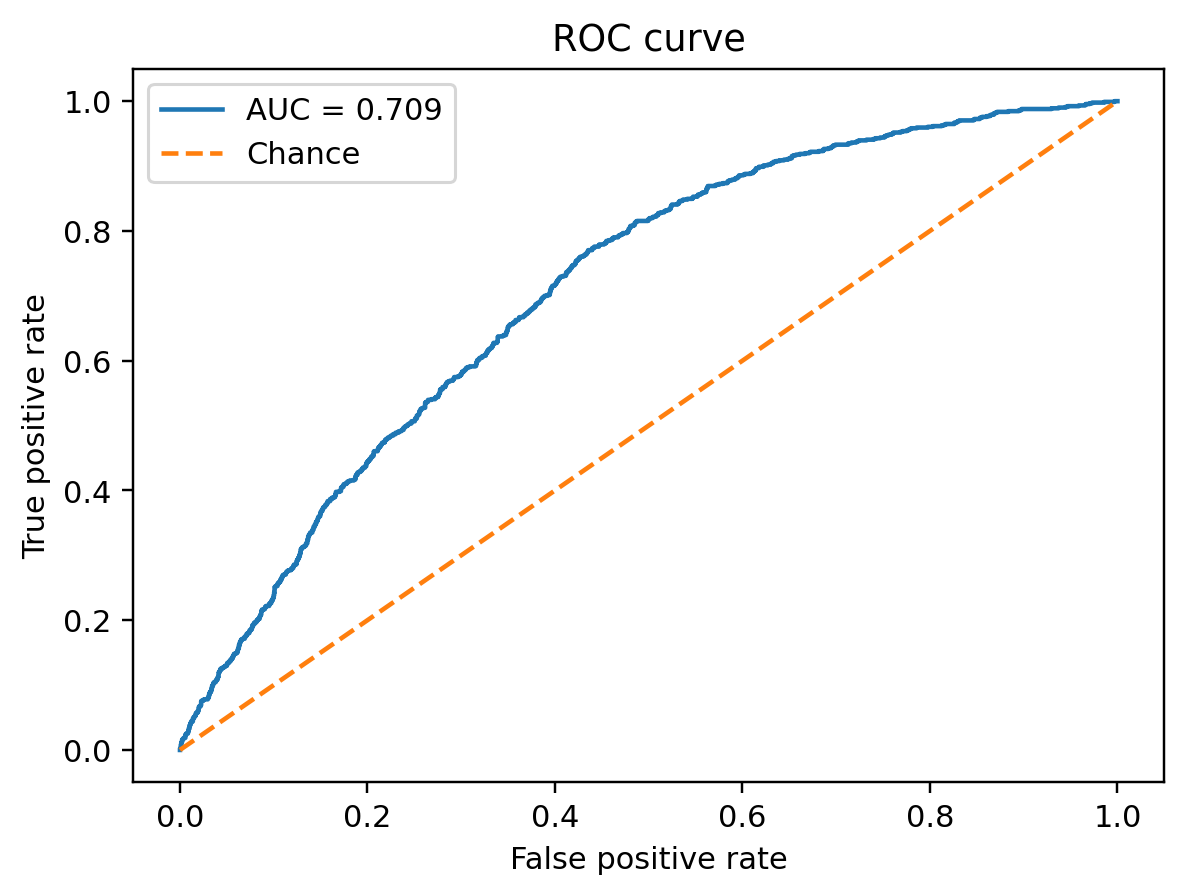


 tfidf_snapshot_3_pr.png


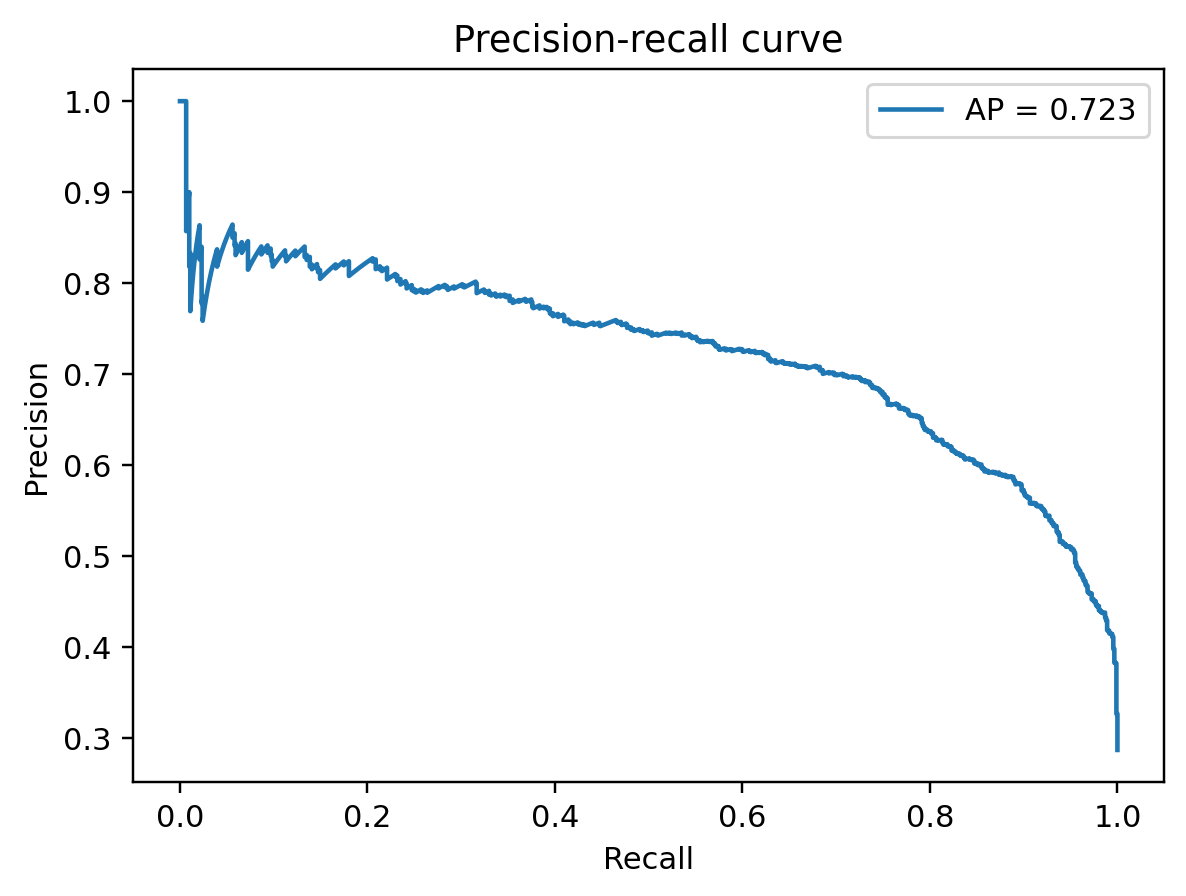


 tfidf_snapshot_3_roc.png


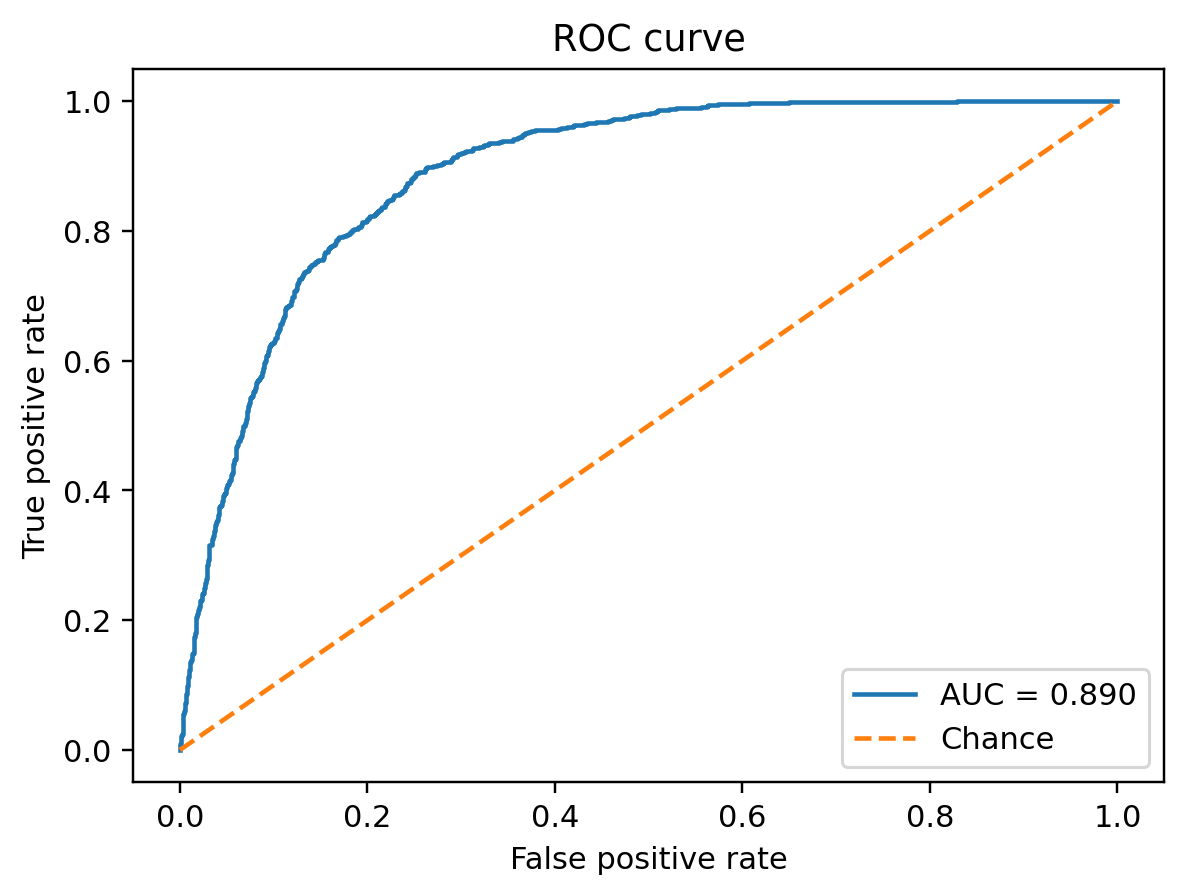


 tfidf_snapshot_4_pr.png


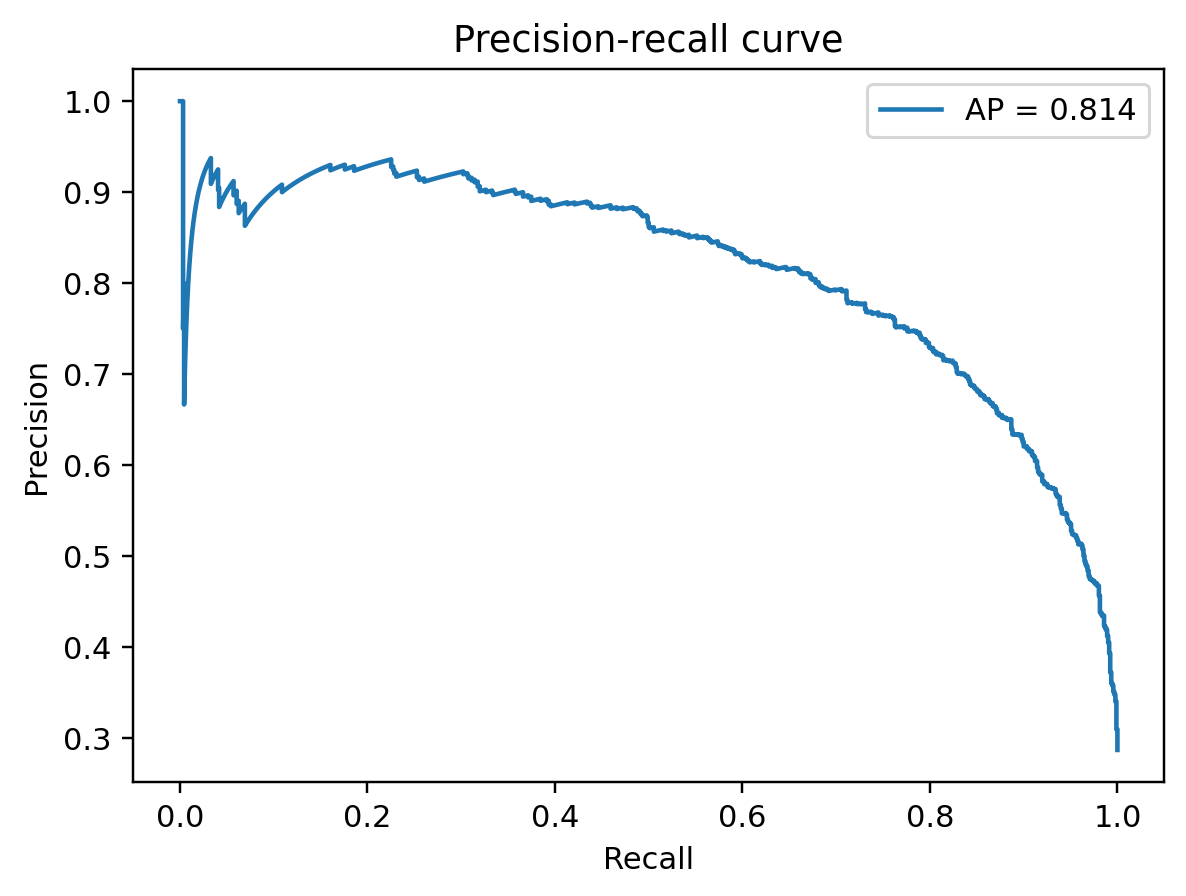


 tfidf_snapshot_4_roc.png


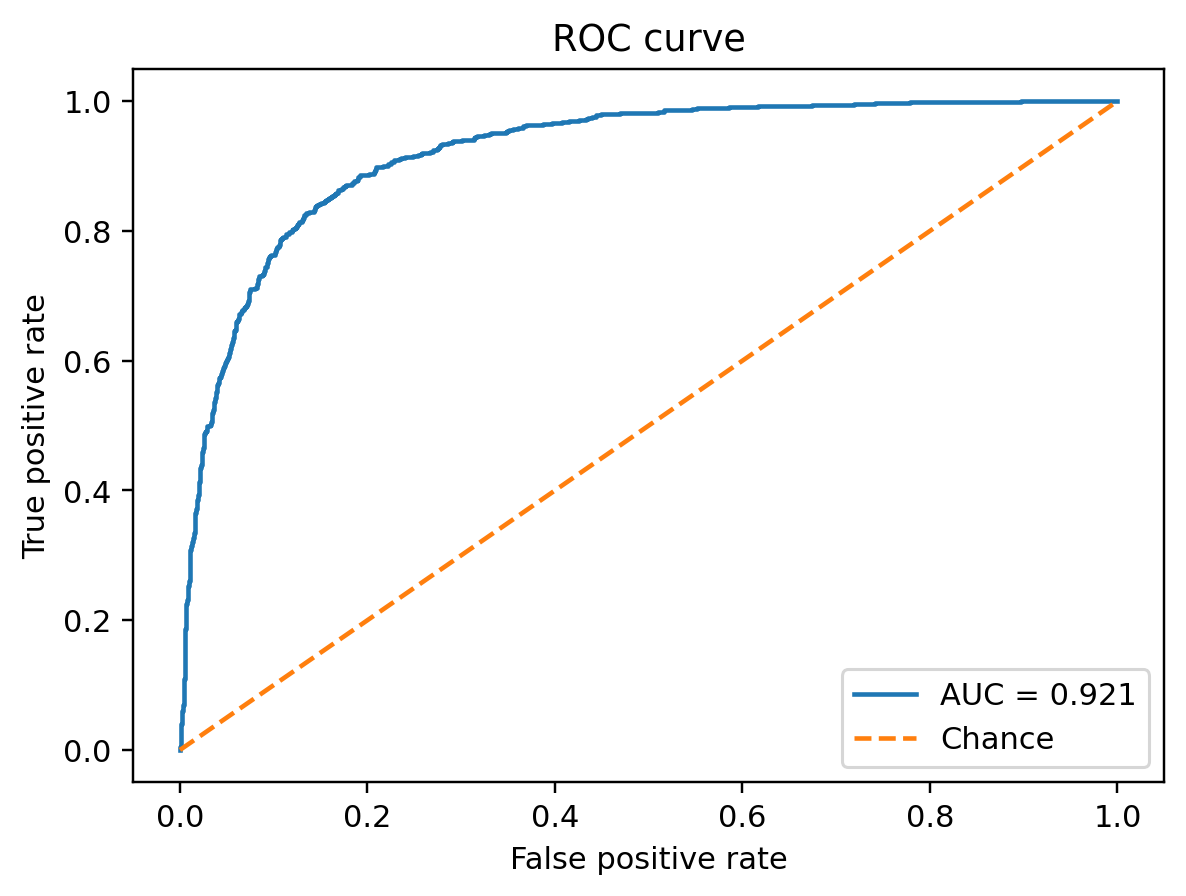

In [42]:
from IPython.display import Image, display
import os

for f in sorted(os.listdir("outputs/figures")):
    if f.endswith(".png"):
        print("\n", f)
        display(
            Image(
                filename="outputs/figures/" + f,
                width=700
            )
        )

In [43]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [44]:
!mkdir -p "/content/drive/MyDrive/Airline_ML_Project"

In [45]:
!cp -r outputs \
"/content/drive/MyDrive/Airline_ML_Project/"

In [46]:
!cp -r data/processed \
"/content/drive/MyDrive/Airline_ML_Project/"

In [47]:
!cp -r scripts \
"/content/drive/MyDrive/Airline_ML_Project/"

In [48]:
!cp -r src \
"/content/drive/MyDrive/Airline_ML_Project/"

!cp config.py requirements.txt README.md \
"/content/drive/MyDrive/Airline_ML_Project/"

In [49]:
!cp -r /content/airline_complexity_ml_project \
"/content/drive/MyDrive/"

In [50]:
!ls "/content/drive/MyDrive/airline_complexity_ml_project"

config.py  Early_Prediction_Airline_Interactions.ipynb	README.md	  src
data	   outputs					requirements.txt
docs	   __pycache__					scripts


In [51]:
!zip -r airline_project_pre_transformer.zip \
airline_complexity_ml_project > /dev/null

In [52]:
!cp airline_project_pre_transformer.zip \
"/content/drive/MyDrive/"

cp: cannot stat 'airline_project_pre_transformer.zip': No such file or directory


In [53]:
!ls -lh "/content/drive/MyDrive/airline_project_pre_transformer.zip"

ls: cannot access '/content/drive/MyDrive/airline_project_pre_transformer.zip': No such file or directory


In [54]:
!ls -ld /content/airline_complexity_ml_project


drwxr-xr-x 8 root root 4096 Nov 15 19:54 /content/airline_complexity_ml_project


In [55]:
%cd /content

/content


In [56]:
!ls

airline_complexity_ml_project
drive
Early_Prediction_Airline_Customer_Service_ML_Project.zip
sample_data


In [57]:
!zip -r airline_project_pre_transformer.zip \
    airline_complexity_ml_project \
    -x "airline_complexity_ml_project/data/raw/*" \
    > /dev/null

In [58]:
!ls -lh /content/airline_project_pre_transformer.zip

-rw-r--r-- 1 root root 101M Nov 15 20:28 /content/airline_project_pre_transformer.zip


In [59]:
!cp /content/airline_project_pre_transformer.zip \
    "/content/drive/MyDrive/"

In [60]:
!ls -lh "/content/drive/MyDrive/airline_project_pre_transformer.zip"

-rw------- 1 root root 101M Nov 15 20:29 /content/drive/MyDrive/airline_project_pre_transformer.zip


In [61]:
/content/drive/MyDrive/airline_complexity_ml_project

NameError: name 'content' is not defined

In [62]:
!ls -lh "/content/drive/MyDrive/airline_complexity_ml_project"

total 37K
-rw------- 1 root root 1.2K Nov 15 20:24 config.py
drwx------ 4 root root 4.0K Nov 15 20:24 data
drwx------ 2 root root 4.0K Nov 15 20:24 docs
-rw------- 1 root root 5.5K Nov 15 20:24 Early_Prediction_Airline_Interactions.ipynb
drwx------ 5 root root 4.0K Nov 15 20:24 outputs
drwx------ 2 root root 4.0K Nov 15 20:24 __pycache__
-rw------- 1 root root 5.5K Nov 15 20:24 README.md
-rw------- 1 root root  190 Nov 15 20:24 requirements.txt
drwx------ 2 root root 4.0K Nov 15 20:24 scripts
drwx------ 3 root root 4.0K Nov 15 20:24 src


In [1]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [2]:
!cp -r "/content/drive/MyDrive/airline_complexity_ml_project" /content/

In [3]:
%cd /content/airline_complexity_ml_project

/content/airline_complexity_ml_project


In [4]:
!ls

config.py  Early_Prediction_Airline_Interactions.ipynb	README.md	  src
data	   outputs					requirements.txt
docs	   __pycache__					scripts


In [5]:
!pip install -q -r requirements.txt

In [6]:
import torch

print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

GPU available: True
GPU: Tesla T4


In [7]:
!python scripts/04_train_sentence_transformer_model.py \
    --snapshot-turns 1

modules.json: 100% 349/349 [00:00<00:00, 1.21MB/s]
config_sentence_transformers.json: 100% 116/116 [00:00<00:00, 407kB/s]
README.md: 100% 10.5k/10.5k [00:00<00:00, 20.8MB/s]
sentence_bert_config.json: 100% 53.0/53.0 [00:00<00:00, 338kB/s]
config.json: 100% 612/612 [00:00<00:00, 2.80MB/s]

model.safetensors: downloading bytes:  91% 83.1M/90.9M [00:01<00:00, 74.3MB/s, 7.11MB/s  ]
model.safetensors: downloading bytes: 100% 85.0M/85.0M [00:01<00:00, 55.4MB/s, 7.92MB/s  ]
model.safetensors: reconstructing file: 100% 90.9M/90.9M [00:01<00:00, 59.2MB/s, 8.77MB/s  ]
Loading weights: 100% 103/103 [00:00<00:00, 4248.84it/s]
tokenizer_config.json: 100% 350/350 [00:00<00:00, 2.16MB/s]
vocab.txt: 100% 232k/232k [00:00<00:00, 16.4MB/s]
tokenizer.json: 100% 466k/466k [00:00<00:00, 55.9MB/s]
special_tokens_map.json: 100% 112/112 [00:00<00:00, 716kB/s]
config.json: 100% 190/190 [00:00<00:00, 1.11MB/s]
Batches: 100% 248/248 [00:10<00:00, 24.66it/s]
{'accuracy': 0.6167192429022083, 'precision': 0.3990734

In [8]:
!ls -lh outputs/metrics

total 88K
-rw------- 1 root root 1.4K Nov 15 20:35 classical_model_summary.csv
-rw------- 1 root root  395 Nov 15 20:35 eda_airline_summary.csv
-rw------- 1 root root  689 Nov 15 20:35 leave_one_airline_out_tfidf_snapshot_1.csv
-rw------- 1 root root  688 Nov 15 20:35 leave_one_airline_out_tfidf_snapshot_2.csv
-rw------- 1 root root  688 Nov 15 20:35 leave_one_airline_out_tfidf_snapshot_3.csv
-rw------- 1 root root  822 Nov 15 20:35 majority_snapshot_1.json
-rw------- 1 root root  822 Nov 15 20:35 majority_snapshot_2.json
-rw------- 1 root root  822 Nov 15 20:35 majority_snapshot_3.json
-rw------- 1 root root  822 Nov 15 20:35 majority_snapshot_4.json
-rw------- 1 root root  534 Nov 15 20:35 random_forest_feature_importance_snapshot_1.csv
-rw------- 1 root root  533 Nov 15 20:35 random_forest_feature_importance_snapshot_2.csv
-rw------- 1 root root  536 Nov 15 20:35 random_forest_feature_importance_snapshot_3.csv
-rw------- 1 root root  536 Nov 15 20:35 random_forest_feature_importance

In [9]:
import os

for f in os.listdir("outputs/metrics"):
    if "sentence" in f.lower() or "transformer" in f.lower():
        print(f)

sentence_transformer_snapshot_1.json


In [10]:
import os

print(os.path.exists("/content/drive/MyDrive"))


True


In [12]:
!mkdir -p "/content/drive/MyDrive/airline_complexity_ml_project"

!rm -rf "/content/drive/MyDrive/airline_complexity_ml_project/outputs"

!cp -r outputs \
"/content/drive/MyDrive/airline_complexity_ml_project/"

In [13]:
!rm -rf "/content/drive/MyDrive/airline_complexity_ml_project/data/processed"

!mkdir -p "/content/drive/MyDrive/airline_complexity_ml_project/data"

!cp -r data/processed \
"/content/drive/MyDrive/airline_complexity_ml_project/data/"

In [14]:
!rm -rf "/content/drive/MyDrive/airline_complexity_ml_project/scripts"
!rm -rf "/content/drive/MyDrive/airline_complexity_ml_project/src"

!cp -r scripts \
"/content/drive/MyDrive/airline_complexity_ml_project/"

!cp -r src \
"/content/drive/MyDrive/airline_complexity_ml_project/"

!cp config.py requirements.txt README.md \
"/content/drive/MyDrive/airline_complexity_ml_project/"

In [15]:
!cp Early_Prediction_Airline_Interactions.ipynb \
"/content/drive/MyDrive/airline_complexity_ml_project/" 2>/dev/null || true

In [16]:
!ls -lh \
"/content/drive/MyDrive/airline_complexity_ml_project/outputs/metrics"

total 23K
-rw------- 1 root root 1.4K Nov 15 20:43 classical_model_summary.csv
-rw------- 1 root root  395 Nov 15 20:43 eda_airline_summary.csv
-rw------- 1 root root  689 Nov 15 20:43 leave_one_airline_out_tfidf_snapshot_1.csv
-rw------- 1 root root  688 Nov 15 20:43 leave_one_airline_out_tfidf_snapshot_2.csv
-rw------- 1 root root  688 Nov 15 20:43 leave_one_airline_out_tfidf_snapshot_3.csv
-rw------- 1 root root  822 Nov 15 20:43 majority_snapshot_1.json
-rw------- 1 root root  822 Nov 15 20:43 majority_snapshot_2.json
-rw------- 1 root root  822 Nov 15 20:43 majority_snapshot_3.json
-rw------- 1 root root  822 Nov 15 20:43 majority_snapshot_4.json
-rw------- 1 root root  534 Nov 15 20:43 random_forest_feature_importance_snapshot_1.csv
-rw------- 1 root root  533 Nov 15 20:43 random_forest_feature_importance_snapshot_2.csv
-rw------- 1 root root  536 Nov 15 20:43 random_forest_feature_importance_snapshot_3.csv
-rw------- 1 root root  536 Nov 15 20:43 random_forest_feature_importance

In [17]:
%cd /content

/content


In [18]:
!zip -r airline_project_after_sentencebert_snapshot1.zip \
    airline_complexity_ml_project \
    -x "airline_complexity_ml_project/data/raw/*" \
    > /dev/null

In [19]:
!ls -lh airline_project_after_sentencebert_snapshot1.zip

-rw-r--r-- 1 root root 101M Nov 15 20:44 airline_project_after_sentencebert_snapshot1.zip


In [20]:
!cp airline_project_after_sentencebert_snapshot1.zip \
"/content/drive/MyDrive/"

In [21]:
!ls -lh \
"/content/drive/MyDrive/airline_project_after_sentencebert_snapshot1.zip"

-rw------- 1 root root 101M Nov 15 20:45 /content/drive/MyDrive/airline_project_after_sentencebert_snapshot1.zip


In [22]:
%cd /content/airline_complexity_ml_project

/content/airline_complexity_ml_project


In [23]:
!pwd

/content/airline_complexity_ml_project


In [24]:
import json

with open(
    "outputs/metrics/sentence_transformer_snapshot_1.json",
    "r"
) as f:
    sentence_results = json.load(f)

sentence_results

{'accuracy': 0.6167192429022083,
 'precision': 0.3990734612839179,
 'recall': 0.6626373626373626,
 'f1': 0.49814126394052044,
 'roc_auc': 0.6671467470582515,
 'average_precision': 0.3950976786500554,
 'classification_report': {'0': {'precision': 0.814948764315853,
   'recall': 0.5982300884955752,
   'f1-score': 0.689971931615208,
   'support': 2260.0},
  '1': {'precision': 0.3990734612839179,
   'recall': 0.6626373626373626,
   'f1-score': 0.49814126394052044,
   'support': 910.0},
  'accuracy': 0.6167192429022083,
  'macro avg': {'precision': 0.6070111127998854,
   'recall': 0.6304337255664689,
   'f1-score': 0.5940565977778642,
   'support': 3170.0},
  'weighted avg': {'precision': 0.6955650022467486,
   'recall': 0.6167192429022083,
   'f1-score': 0.6349038219672692,
   'support': 3170.0}},
 'model': 'sentence_transformer_logreg',
 'encoder': 'sentence-transformers/all-MiniLM-L6-v2',
 'snapshot_turns': 1}

In [25]:
with open(
    "outputs/metrics/tfidf_logreg_snapshot_1.json",
    "r"
) as f:
    tfidf_results = json.load(f)

tfidf_results

{'accuracy': 0.6293375394321766,
 'precision': 0.39923954372623577,
 'recall': 0.5769230769230769,
 'f1': 0.47191011235955055,
 'roc_auc': 0.6575075367110765,
 'average_precision': 0.386757074137071,
 'classification_report': {'0': {'precision': 0.7924528301886793,
   'recall': 0.6504424778761062,
   'f1-score': 0.7144592952612394,
   'support': 2260.0},
  '1': {'precision': 0.39923954372623577,
   'recall': 0.5769230769230769,
   'f1-score': 0.47191011235955055,
   'support': 910.0},
  'accuracy': 0.6293375394321766,
  'macro avg': {'precision': 0.5958461869574575,
   'recall': 0.6136827773995915,
   'f1-score': 0.593184703810395,
   'support': 3170.0},
  'weighted avg': {'precision': 0.6795745681442553,
   'recall': 0.6293375394321766,
   'f1-score': 0.6448316118415117,
   'support': 3170.0}},
 'model': 'tfidf_logreg',
 'snapshot_turns': 1}

In [26]:
with open(
    "outputs/metrics/random_forest_snapshot_1.json",
    "r"
) as f:
    rf_results = json.load(f)

rf_results

{'accuracy': 0.6946372239747634,
 'precision': 0.42892156862745096,
 'recall': 0.19230769230769232,
 'f1': 0.26555386949924126,
 'roc_auc': 0.6476748030730332,
 'average_precision': 0.398958052108541,
 'classification_report': {'0': {'precision': 0.7338884866039103,
   'recall': 0.8969026548672566,
   'f1-score': 0.8072481083233771,
   'support': 2260.0},
  '1': {'precision': 0.42892156862745096,
   'recall': 0.19230769230769232,
   'f1-score': 0.26555386949924126,
   'support': 910.0},
  'accuracy': 0.6946372239747634,
  'macro avg': {'precision': 0.5814050276156806,
   'recall': 0.5446051735874745,
   'f1-score': 0.5364009889113092,
   'support': 3170.0},
  'weighted avg': {'precision': 0.6463427782889014,
   'recall': 0.6946372239747634,
   'f1-score': 0.6517459766735464,
   'support': 3170.0}},
 'model': 'engineered_random_forest',
 'snapshot_turns': 1}

In [27]:
!python scripts/04_train_sentence_transformer_model.py \
    --snapshot-turns 2

Loading weights: 100% 103/103 [00:00<00:00, 4340.97it/s]
Batches: 100% 248/248 [00:14<00:00, 16.70it/s]
{'accuracy': 0.6261829652996845, 'precision': 0.41168914579319205, 'recall': 0.7043956043956044, 'f1': 0.5196595054722335, 'roc_auc': 0.6959588641447049, 'average_precision': 0.42912042416139434, 'classification_report': {'0': {'precision': 0.8332300061996281, 'recall': 0.5946902654867257, 'f1-score': 0.6940356312935708, 'support': 2260.0}, '1': {'precision': 0.41168914579319205, 'recall': 0.7043956043956044, 'f1-score': 0.5196595054722335, 'support': 910.0}, 'accuracy': 0.6261829652996845, 'macro avg': {'precision': 0.62245957599641, 'recall': 0.649542934941165, 'f1-score': 0.6068475683829022, 'support': 3170.0}, 'weighted avg': {'precision': 0.7122198538432064, 'recall': 0.6261829652996845, 'f1-score': 0.6439781314521144, 'support': 3170.0}}, 'model': 'sentence_transformer_logreg', 'encoder': 'sentence-transformers/all-MiniLM-L6-v2', 'snapshot_turns': 2}


In [28]:
!python scripts/04_train_sentence_transformer_model.py \
    --snapshot-turns 3

Loading weights: 100% 103/103 [00:00<00:00, 5506.44it/s]
Batches: 100% 248/248 [00:19<00:00, 13.00it/s]
{'accuracy': 0.7277602523659306, 'precision': 0.517709118311982, 'recall': 0.7549450549450549, 'f1': 0.6142154671434957, 'roc_auc': 0.8188150345229992, 'average_precision': 0.6187989633068958, 'classification_report': {'0': {'precision': 0.8790016277807922, 'recall': 0.7168141592920354, 'f1-score': 0.78966609797709, 'support': 2260.0}, '1': {'precision': 0.517709118311982, 'recall': 0.7549450549450549, 'f1-score': 0.6142154671434957, 'support': 910.0}, 'accuracy': 0.7277602523659306, 'macro avg': {'precision': 0.6983553730463871, 'recall': 0.7358796071185452, 'f1-score': 0.7019407825602928, 'support': 3170.0}, 'weighted avg': {'precision': 0.7752867433591463, 'recall': 0.7277602523659306, 'f1-score': 0.7393001440153958, 'support': 3170.0}}, 'model': 'sentence_transformer_logreg', 'encoder': 'sentence-transformers/all-MiniLM-L6-v2', 'snapshot_turns': 3}


In [29]:
import json

with open(
    "outputs/metrics/sentence_transformer_snapshot_2.json",
    "r"
) as f:
    sbert2 = json.load(f)

sbert2

{'accuracy': 0.6261829652996845,
 'precision': 0.41168914579319205,
 'recall': 0.7043956043956044,
 'f1': 0.5196595054722335,
 'roc_auc': 0.6959588641447049,
 'average_precision': 0.42912042416139434,
 'classification_report': {'0': {'precision': 0.8332300061996281,
   'recall': 0.5946902654867257,
   'f1-score': 0.6940356312935708,
   'support': 2260.0},
  '1': {'precision': 0.41168914579319205,
   'recall': 0.7043956043956044,
   'f1-score': 0.5196595054722335,
   'support': 910.0},
  'accuracy': 0.6261829652996845,
  'macro avg': {'precision': 0.62245957599641,
   'recall': 0.649542934941165,
   'f1-score': 0.6068475683829022,
   'support': 3170.0},
  'weighted avg': {'precision': 0.7122198538432064,
   'recall': 0.6261829652996845,
   'f1-score': 0.6439781314521144,
   'support': 3170.0}},
 'model': 'sentence_transformer_logreg',
 'encoder': 'sentence-transformers/all-MiniLM-L6-v2',
 'snapshot_turns': 2}

In [30]:
with open(
    "outputs/metrics/sentence_transformer_snapshot_3.json",
    "r"
) as f:
    sbert3 = json.load(f)

sbert3

{'accuracy': 0.7277602523659306,
 'precision': 0.517709118311982,
 'recall': 0.7549450549450549,
 'f1': 0.6142154671434957,
 'roc_auc': 0.8188150345229992,
 'average_precision': 0.6187989633068958,
 'classification_report': {'0': {'precision': 0.8790016277807922,
   'recall': 0.7168141592920354,
   'f1-score': 0.78966609797709,
   'support': 2260.0},
  '1': {'precision': 0.517709118311982,
   'recall': 0.7549450549450549,
   'f1-score': 0.6142154671434957,
   'support': 910.0},
  'accuracy': 0.7277602523659306,
  'macro avg': {'precision': 0.6983553730463871,
   'recall': 0.7358796071185452,
   'f1-score': 0.7019407825602928,
   'support': 3170.0},
  'weighted avg': {'precision': 0.7752867433591463,
   'recall': 0.7277602523659306,
   'f1-score': 0.7393001440153958,
   'support': 3170.0}},
 'model': 'sentence_transformer_logreg',
 'encoder': 'sentence-transformers/all-MiniLM-L6-v2',
 'snapshot_turns': 3}

In [31]:
import pandas as pd

comparison = pd.DataFrame([
    {
        "Snapshot": 1,
        "Accuracy": sentence_results["accuracy"],
        "Precision": sentence_results["precision"],
        "Recall": sentence_results["recall"],
        "F1": sentence_results["f1"],
        "ROC_AUC": sentence_results["roc_auc"]
    },
    {
        "Snapshot": 2,
        "Accuracy": sbert2["accuracy"],
        "Precision": sbert2["precision"],
        "Recall": sbert2["recall"],
        "F1": sbert2["f1"],
        "ROC_AUC": sbert2["roc_auc"]
    },
    {
        "Snapshot": 3,
        "Accuracy": sbert3["accuracy"],
        "Precision": sbert3["precision"],
        "Recall": sbert3["recall"],
        "F1": sbert3["f1"],
        "ROC_AUC": sbert3["roc_auc"]
    }
])

comparison

,Snapshot,Accuracy,Precision,Recall,F1,ROC_AUC
0,1,0.616719,0.399073,0.662637,0.498141,0.667147
1,2,0.626183,0.411689,0.704396,0.519660,0.695959
2,3,0.727760,0.517709,0.754945,0.614215,0.818815


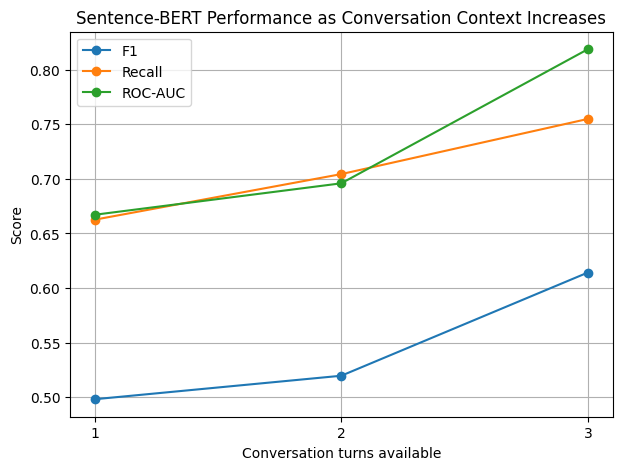

In [32]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7,5))

plt.plot(
    comparison["Snapshot"],
    comparison["F1"],
    marker="o",
    label="F1"
)

plt.plot(
    comparison["Snapshot"],
    comparison["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    comparison["Snapshot"],
    comparison["ROC_AUC"],
    marker="o",
    label="ROC-AUC"
)

plt.xlabel("Conversation turns available")
plt.ylabel("Score")
plt.title("Sentence-BERT Performance as Conversation Context Increases")
plt.xticks([1,2,3])
plt.legend()
plt.grid(True)

plt.savefig(
    "outputs/figures/sentencebert_performance_by_snapshot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()